# IncreaseAcc1.ipynb – Stage 4 Classical ML (RF / XGB / SVM)
**Project:** `/lp-dev/23BRS1328/erp_trial_min`  
**GPU:** NVIDIA A100 (Brev)  
**Goal:** Kill any running shards → clean stale markers if needed → retrain all 3 models → evaluate & visualize results.

---
### Table of Contents
1. [Setup & Paths](#1)
2. [Kill Running Stage-4 Processes](#2)
3. [Marker Audit](#3)
4. [Optional: Wipe Markers for Full Re-train](#4)
5. [Upgrade models.py – GPU XGBoost + Better Hyperparams](#5)
6. [Launch Stage-4 Shards (4-way parallel)](#6)
7. [Monitor Shard Progress](#7)
8. [Load & Inspect Results CSV](#8)
9. [Per-Paradigm / Per-Step / Per-Model Analysis](#9)
10. [Visualizations](#10)
11. [Best Model per Paradigm](#11)
12. [Hyperparameter Sensitivity (Optional Tuning)](#12)
13. [Final Summary](#13)


---
## 1 · Setup & Paths <a id='1'></a>

In [84]:
import os, sys, subprocess, time, glob
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ── Project root ──────────────────────────────────────────────────────────────
ROOT        = Path('/lp-dev/23BRS1328/erp_trial_min')
STAGE4_DIR  = ROOT / 'stage4_classical_ml'
OUT_ROOT    = ROOT / 'results_stage4_classical_ml'
MARKER_DIR  = OUT_ROOT / 'markers'
CSV_PATH    = OUT_ROOT / 'stage4_accuracy_upto_current_markers.csv'
LOG_DIR     = ROOT   # logs_shard*.log live at project root

os.chdir(ROOT)
print('CWD :', os.getcwd())
print('ROOT exists:', ROOT.exists())
print('MARKER_DIR exists:', MARKER_DIR.exists())


CWD : /lp-dev/23BRS1328/erp_trial_min
ROOT exists: True
MARKER_DIR exists: True


---
## 2 · Kill Running Stage-4 Processes <a id='2'></a>
> **Run this first** to stop all background `run_stage1_classical_ml.py` processes before re-launching.

In [2]:
# ── Find PIDs of any running Stage-4 shards ───────────────────────────────────
result = subprocess.run(
    ['pgrep', '-fa', 'run_stage1_classical_ml.py'],
    capture_output=True, text=True
)
print('Currently running Stage-4 processes:')
print(result.stdout if result.stdout else '  (none found)')


Currently running Stage-4 processes:
  (none found)


In [3]:
# ── Kill them all ─────────────────────────────────────────────────────────────
kill_result = subprocess.run(
    ['pkill', '-f', 'run_stage1_classical_ml.py'],
    capture_output=True, text=True
)
time.sleep(2)

# Verify
check = subprocess.run(
    ['pgrep', '-fa', 'run_stage1_classical_ml.py'],
    capture_output=True, text=True
)
if check.stdout.strip():
    print('⚠ Some processes still alive:')
    print(check.stdout)
else:
    print('✅ All Stage-4 processes terminated.')


✅ All Stage-4 processes terminated.


---
## 3 · Marker Audit <a id='3'></a>

In [4]:
# ── Count existing markers ────────────────────────────────────────────────────
markers = sorted(MARKER_DIR.glob('*.done'))
print(f'Markers found : {len(markers)}')

# ── Expected total from dataset.py ───────────────────────────────────────────
sys.path.insert(0, str(STAGE4_DIR))
from dataset import get_paradigms, STEPS

all_paradigms   = get_paradigms()
MODEL_BUILDERS  = ['random_forest', 'xgboost', 'svm']
total_expected  = len(all_paradigms) * len(MODEL_BUILDERS) * len(STEPS)

print(f'Paradigms     : {len(all_paradigms)}')
print(f'Steps         : {len(STEPS)}  → {STEPS}')
print(f'Models        : {len(MODEL_BUILDERS)}')
print(f'Expected total: {total_expected}')
print(f'Missing       : {total_expected - len(markers)}')


Markers found : 599
Paradigms     : 22
Steps         : 10  → ['5', '10', '20', '30', '50', '75', '100', '150', '200', 'full']
Models        : 3
Expected total: 660
Missing       : 61


In [5]:
# ── Break down existing markers by model ─────────────────────────────────────
from collections import Counter

counts = Counter()
for m in markers:
    # marker filename format: {model}__{paradigm}__{step}.done
    parts = m.stem.split('__')
    if parts:
        counts[parts[0]] += 1

print('Marker counts by model:')
for model, cnt in sorted(counts.items()):
    print(f'  {model:20s}: {cnt}')


Marker counts by model:
  random_forest       : 200
  svm                 : 199
  xgboost             : 200


---
## 4 · Wipe Markers for Full Re-train (Optional) <a id='4'></a>
> **Uncomment and run only if you want a clean second run.**  
> All existing result CSVs are kept; only `.done` sentinel files are removed.
> The existing result CSVs (RF / XGB / SVM subdirectories) will be **overwritten** by the new run, so if you want to keep them, back them up first.

In [22]:
from pathlib import Path

ROOT       = Path('/lp-dev/23BRS1328/erp_trial_min')
MARKER_DIR = ROOT / 'results_stage4_classical_ml' / 'markers'

markers = list(MARKER_DIR.glob('*.done'))
print(f'Markers before wipe: {len(markers)}')

for m in markers:
    m.unlink()

remaining = list(MARKER_DIR.glob('*.done'))
print(f'Markers after wipe : {len(remaining)}')
assert remaining == [], "Wipe failed — markers still exist!"
print('✅ Ready for clean re-train')

Markers before wipe: 0
Markers after wipe : 0
✅ Ready for clean re-train


---
## 5 · Upgrade models.py – GPU XGBoost + Better Hyperparams <a id='5'></a>
This cell **patches** `models.py` in-place with:
- XGBoost → A100 GPU via `device='cuda'` (XGB ≥ 2.0) or `tree_method='gpu_hist'` fallback.
- More trees (RF: 300 → 500), deeper trees, better SVM `C`.
- A **backup** of the original is saved as `models_backup_run1.py`.

> **Safety:** The driver `run_stage1_classical_ml.py` is NOT touched.

In [23]:
# ── First, show current models.py ────────────────────────────────────────────
models_path = STAGE4_DIR / 'models.py'
print(models_path.read_text())


"""
models.py  –  Stage 4 Classical ML model builders
Run 2  (IncreaseAcc1):  Improved hyperparams + GPU XGBoost
Anti-overfitting measures applied to all three models.
Original backed up as models_backup_run1.py
"""
import os
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
import xgboost as xgb

# ─── GPU toggle ───────────────────────────────────────────────────────────────
# Set env var STAGE4_USE_GPU=0 to force CPU (default: GPU on)
USE_GPU = os.environ.get("STAGE4_USE_GPU", "1") == "1"

# Detect XGBoost version for correct GPU kwarg (>=2.0 uses device=)
try:
    import packaging.version as _pv
    _XGB_GE_2 = _pv.parse(xgb.__version__) >= _pv.parse("2.0.0")
except Exception:
    _XGB_GE_2 = False


# ─────────────────────────────────────────────────────────────────────────────
def build_random_forest(**kwargs):
    """
    Random Forest  –  Run 2 defaults.
    Anti-overfitting: max_depth=20, min_samples_leaf=4, balanced weights.
    """
    params = 

In [25]:
import os, subprocess

ROOT      = Path('/lp-dev/23BRS1328/erp_trial_min')
NUM_SHARDS = 4

os.environ['STAGE4_USE_GPU'] = '1'   # pass GPU flag to child processes

shard_procs = {}

for shard_idx in range(NUM_SHARDS):
    log_file = ROOT / f'logs_shard{shard_idx}_run2.log'
    cmd = [
        'python3',
        str(ROOT / 'stage4_classical_ml' / 'run_stage1_classical_ml.py'),
        '--shard-index', str(shard_idx),
        '--num-shards',  str(NUM_SHARDS),
    ]
    env = {**os.environ}          # inherits STAGE4_USE_GPU=1
    with open(log_file, 'w') as lf:
        proc = subprocess.Popen(
            cmd,
            stdout=lf,
            stderr=subprocess.STDOUT,
            cwd=str(ROOT),
            env=env
        )
    shard_procs[shard_idx] = proc
    print(f'Shard {shard_idx}  PID={proc.pid}  log={log_file.name}')

print('\n✅ All 4 shards launched.')

Shard 0  PID=2171858  log=logs_shard0_run2.log
Shard 1  PID=2171859  log=logs_shard1_run2.log
Shard 2  PID=2171860  log=logs_shard2_run2.log
Shard 3  PID=2171861  log=logs_shard3_run2.log

✅ All 4 shards launched.


In [27]:
import sys
from pathlib import Path
from collections import Counter

ROOT = Path('/lp-dev/23BRS1328/erp_trial_min')
MARKER_DIR = ROOT / 'results_stage4_classical_ml' / 'markers'

sys.path.insert(0, str(ROOT / 'stage4_classical_ml'))
from dataset import get_paradigms, STEPS

MODEL_BUILDERS  = ['random_forest', 'xgboost', 'svm']
total_expected  = len(get_paradigms()) * len(MODEL_BUILDERS) * len(STEPS)
n_done          = len(list(MARKER_DIR.glob('*.done')))
pct             = 100 * n_done / total_expected if total_expected else 0

bar = '█' * int(pct // 2) + '░' * (50 - int(pct // 2))
print(f'[{bar}] {pct:.1f}%  ({n_done}/{total_expected})')

counts = Counter(m.stem.split('__')[0] for m in MARKER_DIR.glob('*.done'))
per_expected = total_expected // len(MODEL_BUILDERS)
for model in MODEL_BUILDERS:
    print(f'  {model:20s}: {counts.get(model,0):3d} / {per_expected}')

[█████████████████████████████░░░░░░░░░░░░░░░░░░░░░] 59.7%  (394/660)
  random_forest       : 134 / 220
  xgboost             : 130 / 220
  svm                 : 130 / 220


In [37]:
import subprocess, time
from pathlib import Path
from collections import Counter

ROOT = Path('/lp-dev/23BRS1328/erp_trial_min')
MARKER_DIR = ROOT / 'results_stage4_classical_ml' / 'markers'
NUM_SHARDS = 4

print("=" * 70)
print("1. ACTIVE PROCESS CHECK")
print("=" * 70)

# Check active Python processes for the driver
ps_check = subprocess.run(
    ['pgrep', '-fa', 'run_stage1_classical_ml.py'],
    capture_output=True, text=True
)

running_processes = [line for line in ps_check.stdout.strip().split('\n') if line]

if running_processes:
    print(f"✅ {len(running_processes)} Shard Process(es) Running:")
    for proc in running_processes:
        print(f"   • {proc}")
else:
    print("❌ No active shard processes found!")

print("\n" + "=" * 70)
print("2. MARKER PROGRESS")
print("=" * 70)

markers = list(MARKER_DIR.glob('*.done'))
total_expected = 660  # ~22 paradigms * 3 models * 10 steps
pct = (len(markers) / total_expected) * 100 if total_expected else 0

bar = '█' * int(pct // 2) + '░' * (50 - int(pct // 2))
print(f"[{bar}] {pct:.1f}% ({len(markers)} / {total_expected} markers done)\n")

counts = Counter(m.stem.split('__')[0] for m in markers)
for model in ['random_forest', 'xgboost', 'svm']:
    print(f"   • {model:15s}: {counts.get(model, 0)} done")

print("\n" + "=" * 70)
print("3. RECENT SHARD LOGS (Last 5 lines each)")
print("=" * 70)

for i in range(NUM_SHARDS):
    log_file = ROOT / f'logs_shard{i}_run2.log'
    print(f"\n--- Shard {i} ({log_file.name}) ---")
    if log_file.exists():
        lines = log_file.read_text(errors='replace').strip().split('\n')
        tail = lines[-5:] if len(lines) >= 5 else lines
        print("\n".join(tail) if tail else "   (log file is currently empty)")
    else:
        print("   (log file does not exist yet)")

print("\n" + "=" * 70)
print("4. GPU UTILIZATION")
print("=" * 70)
try:
    gpu = subprocess.run(
        ['nvidia-smi', '--query-gpu=name,utilization.gpu,memory.used,memory.total', '--format=csv,noheader'],
        capture_output=True, text=True
    )
    print("GPU Status:", gpu.stdout.strip() if gpu.stdout else "N/A")
except Exception as e:
    print(f"Could not query GPU: {e}")

1. ACTIVE PROCESS CHECK
❌ No active shard processes found!

2. MARKER PROGRESS
[██████████████████████████████████████████████████] 100.0% (660 / 660 markers done)

   • random_forest  : 220 done
   • xgboost        : 220 done
   • svm            : 220 done

3. RECENT SHARD LOGS (Last 5 lines each)

--- Shard 0 (logs_shard0_run2.log) ---
[FOLD ERROR] model=svm paradigm=ERP_CORE__N400 step=full subject=sub-040: AttributeError("'SVMModel' object has no attribute 'train_predict'")
[NO DATA] model=svm paradigm=ERP_CORE__N400 step=full
[TIME] svm / ERP_CORE__N400 step=full: 1.2s

Shard 0 complete.

--- Shard 1 (logs_shard1_run2.log) ---
[FOLD ERROR] model=svm paradigm=ERP_CORE__P3 step=full subject=sub-040: AttributeError("'SVMModel' object has no attribute 'train_predict'")
[NO DATA] model=svm paradigm=ERP_CORE__P3 step=full
[TIME] svm / ERP_CORE__P3 step=full: 0.7s

Shard 1 complete.

--- Shard 2 (logs_shard2_run2.log) ---
[FOLD ERROR] model=svm paradigm=ERP_CORE__N170 step=full subject=s

> **⚠️ IMPORTANT – Check your original `models.py` interface before writing.**  
> If your original file uses a different function registry format (e.g. a dict `MODEL_BUILDERS` with lambdas, or a factory function called differently), adapt the cell above to match.  
> The driver `run_stage1_classical_ml.py` must be able to import and call builders in the same way as before.

In [38]:
from pathlib import Path
import pandas as pd

ROOT     = Path('/lp-dev/23BRS1328/erp_trial_min')
OUT_ROOT = ROOT / 'results_stage4_classical_ml'

# Re-run evaluation to get current CSV
import subprocess
result = subprocess.run(
    ['python3', 'stage4_classical_ml/eval_stage1_accuracy_upto_markers.py'],
    capture_output=True, text=True, cwd=str(ROOT)
)
print(result.stdout)
print(result.stderr[-1000:] if result.stderr else '')


Per-model accuracy up to current markers:

random_forest: accuracy_mean=0.5824, balanced_accuracy_mean=0.5352
svm: accuracy_mean=0.5811, balanced_accuracy_mean=0.5390
xgboost: accuracy_mean=0.5720, balanced_accuracy_mean=0.5367

Saved detailed table to /lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/stage4_accuracy_upto_current_markers.csv




In [40]:
import pandas as pd
from pathlib import Path

OUT_ROOT = Path('/lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml')
summary_csv = OUT_ROOT / 'stage4_accuracy_upto_current_markers.csv'

df = pd.read_csv(summary_csv)
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst 3 rows:")
print(df.head(3).to_string())

Shape: (572, 9)

Columns: ['dataset_task', 'model', 'step', 'n_folds', 'n_degenerate_folds', 'accuracy_mean', 'balanced_accuracy_mean', 'macro_f1_mean', 'auc_mean']

First 3 rows:
         dataset_task          model step  n_folds  n_degenerate_folds  accuracy_mean  balanced_accuracy_mean  macro_f1_mean  auc_mean
0  DS002680__gonogo_1  random_forest    5       10                   0       0.527100                0.545023       0.389366  0.568063
1  DS002680__gonogo_1  random_forest   10       10                   0       0.534145                0.553651       0.392928  0.530102
2  DS002680__gonogo_1  random_forest   20       10                   0       0.526898                0.550000       0.383837  0.528063


In [41]:
import subprocess

result = subprocess.run(
    ['find', '/lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml', 
     '-name', '*.csv', '-o', '-name', '*.pkl', '-o', '-name', '*.json'],
    capture_output=True, text=True
)
files = [f for f in result.stdout.strip().split('\n') if f]
print(f"All result files found: {len(files)}")
for f in files[:30]:
    print(" •", f)

All result files found: 1273
 • /lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/random_forest/DS002680__gonogo_1/step_5_folds.csv
 • /lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/random_forest/DS002680__gonogo_1/DS002680__gonogo_1_summary.csv
 • /lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/random_forest/DS002680__gonogo_1/step_10_folds.csv
 • /lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/random_forest/DS002680__gonogo_1/step_20_folds.csv
 • /lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/random_forest/DS002680__gonogo_1/step_30_folds.csv
 • /lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/random_forest/DS002680__gonogo_1/step_50_folds.csv
 • /lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/random_forest/DS002680__gonogo_1/step_75_folds.csv
 • /lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/random_forest/DS002680__gonogo_1/step_100_folds.csv
 • /lp-dev/23BRS1328/erp_trial_min/results_sta

In [42]:
import pandas as pd
from pathlib import Path

OUT_ROOT = Path('/lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml')

summary_dfs = []

for model in ['random_forest', 'xgboost', 'svm']:
    model_dir = OUT_ROOT / model
    # Collect all _summary.csv files (one per paradigm)
    summary_files = list(model_dir.glob('**/*_summary.csv'))
    print(f"\n{model}: {len(summary_files)} paradigm summary files")
    
    for sf in summary_files:
        try:
            df = pd.read_csv(sf)
            df['model'] = model
            df['paradigm'] = sf.parent.name
            summary_dfs.append(df)
        except Exception as e:
            print(f"  ⚠ Could not read {sf.name}: {e}")

if summary_dfs:
    all_df = pd.concat(summary_dfs, ignore_index=True)
    print(f"\n✅ Total rows loaded: {len(all_df)}")
    print("Columns:", all_df.columns.tolist())
    print("\nFirst 3 rows:")
    print(all_df.head(3).to_string())
else:
    print("❌ No summary files found")


random_forest: 20 paradigm summary files

xgboost: 20 paradigm summary files

svm: 20 paradigm summary files

✅ Total rows loaded: 572
Columns: ['dataset_task', 'model', 'step', 'n_folds', 'n_degenerate_folds', 'accuracy_mean', 'balanced_accuracy_mean', 'macro_f1_mean', 'auc_mean', 'paradigm']

First 3 rows:
         dataset_task          model step  n_folds  n_degenerate_folds  accuracy_mean  balanced_accuracy_mean  macro_f1_mean  auc_mean            paradigm
0  DS002680__gonogo_1  random_forest    5       10                   0       0.527100                0.545023       0.389366  0.568063  DS002680__gonogo_1
1  DS002680__gonogo_1  random_forest   10       10                   0       0.534145                0.553651       0.392928  0.530102  DS002680__gonogo_1
2  DS002680__gonogo_1  random_forest   20       10                   0       0.526898                0.550000       0.383837  0.528063  DS002680__gonogo_1


In [49]:
import subprocess, time
from pathlib import Path
from collections import Counter

ROOT       = Path('/lp-dev/23BRS1328/erp_trial_min')
OUT_ROOT   = ROOT / 'results_stage4_classical_ml'
MARKER_DIR = OUT_ROOT / 'markers'

# ── 1. Are processes alive? ────────────────────────────────────────────────────
print("=" * 60)
print("1. ACTIVE SHARD PROCESSES")
print("=" * 60)
ps = subprocess.run(['pgrep', '-fa', 'run_stage1_classical_ml.py'],
                    capture_output=True, text=True)
procs = [l for l in ps.stdout.strip().split('\n') if l]
if procs:
    print(f"✅ {len(procs)} shard(s) running:")
    for p in procs: print(f"   • {p}")
else:
    print("❌ No shard processes found — training not running!")

# ── 2. Marker counts ───────────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("2. MARKER COUNTS")
print("=" * 60)
counts = Counter(m.stem.split('__')[0] for m in MARKER_DIR.glob('*.done'))
for model in ['random_forest', 'xgboost', 'svm']:
    status = "✅" if counts.get(model, 0) == 220 else "🔄"
    print(f"  {status} {model:20s}: {counts.get(model, 0)} / 220 done")

# ── 3. SVM CSV files being created? ────────────────────────────────────────────
print("\n" + "=" * 60)
print("3. SVM RESULT FILES")
print("=" * 60)
svm_csvs = list((OUT_ROOT / 'svm').glob('**/*.csv'))
print(f"  SVM CSV files: {len(svm_csvs)}")
if svm_csvs:
    print("  Most recent:")
    latest = sorted(svm_csvs, key=lambda f: f.stat().st_mtime, reverse=True)[:3]
    for f in latest:
        print(f"    • {f.parent.name}/{f.name}")

# ── 4. Check logs for errors vs progress ───────────────────────────────────────
print("\n" + "=" * 60)
print("4. SVM SHARD LOGS (last 6 lines each)")
print("=" * 60)
any_error = False
for i in range(4):
    # check both run3_svm and run2 log names
    for suffix in [f'run3_svm', f'run3']:
        log_path = ROOT / f'logs_shard{i}_{suffix}.log'
        if log_path.exists():
            lines = log_path.read_text(errors='replace').strip().split('\n')
            tail  = lines[-6:]
            print(f"\n--- Shard {i} ({log_path.name}) ---")
            for l in tail:
                print(f"  {l}")
                if 'AttributeError' in l or 'Error' in l or 'Traceback' in l:
                    any_error = True
            break

print("\n" + "=" * 60)
if any_error:
    print("⚠  Errors detected in logs — check above")
else:
    print("✅ No errors detected in logs")

1. ACTIVE SHARD PROCESSES
✅ 4 shard(s) running:
   • 2438134 python3 stage4_classical_ml/run_stage1_classical_ml.py --shard-index 0 --num-shards 4
   • 2438135 python3 stage4_classical_ml/run_stage1_classical_ml.py --shard-index 1 --num-shards 4
   • 2438136 python3 stage4_classical_ml/run_stage1_classical_ml.py --shard-index 2 --num-shards 4
   • 2438137 python3 stage4_classical_ml/run_stage1_classical_ml.py --shard-index 3 --num-shards 4

2. MARKER COUNTS
  ✅ random_forest       : 220 / 220 done
  ✅ xgboost             : 220 / 220 done
  🔄 svm                 : 160 / 220 done

3. SVM RESULT FILES
  SVM CSV files: 210
  Most recent:
    • DS006018__auditoryoddball/DS006018__auditoryoddball_summary.csv
    • DS006018__auditoryoddball/step_30_folds.csv
    • ERP_CORE__LRP/ERP_CORE__LRP_summary.csv

4. SVM SHARD LOGS (last 6 lines each)

--- Shard 0 (logs_shard0_run3_svm.log) ---
  [FOLD ERROR] model=svm paradigm=ERP_CORE__LRP step=200 subject=sub-016: AttributeError("'SVMModel' object h

In [53]:
# Run this in notebook to check SVM completion
from pathlib import Path
MARKER_DIR = Path('/lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/markers')
svm = len(list(MARKER_DIR.glob('svm__*.done')))
rf  = len(list(MARKER_DIR.glob('random_forest__*.done')))
xgb = len(list(MARKER_DIR.glob('xgboost__*.done')))
print(f"RF={rf}/220  XGB={xgb}/220  SVM={svm}/220")
print("✅ All done!" if svm == 220 else f"⏳ SVM still running... {svm}/220")

RF=220/220  XGB=220/220  SVM=162/220
⏳ SVM still running... 162/220


In [53]:
import subprocess, time
from IPython.display import clear_output
from pathlib import Path
from collections import Counter

ROOT       = Path('/lp-dev/23BRS1328/erp_trial_min')
MARKER_DIR = ROOT / 'results_stage4_classical_ml' / 'markers'

while True:
    clear_output(wait=True)

    counts   = Counter(m.stem.split('__')[0] for m in MARKER_DIR.glob('*.done'))
    rf_done  = counts.get('random_forest', 0)
    xgb_done = counts.get('xgboost', 0)
    svm_done = counts.get('svm', 0)
    total    = rf_done + xgb_done + svm_done
    pct      = total / 660 * 100
    bar      = '█' * int(pct // 2) + '░' * (50 - int(pct // 2))

    print("=" * 65)
    print(f"  STAGE 4  —  {time.strftime('%Y-%m-%d %H:%M:%S')}")
    print("=" * 65)
    print(f"\n  [{bar}] {total}/660 ({pct:.1f}%)\n")

    for name, done in [('random_forest', rf_done),
                       ('xgboost',       xgb_done),
                       ('svm',           svm_done)]:
        icon     = '✅' if done == 220 else '🔄'
        note     = '(COMPLETE)' if done == 220 else f'{220 - done} remaining'
        print(f"  {icon} {name:20s}: {done}/220  {note}")

    # Active shards
    ps    = subprocess.run(['pgrep', '-fa', 'run_stage1_classical_ml.py'],
                           capture_output=True, text=True)
    procs = [l for l in ps.stdout.strip().split('\n') if l]
    print(f"\n  Shards: {'✅' if len(procs) >= 1 else '❌'} {len(procs)} running")

    # Last log line per shard (skip warnings)
    for i in range(4):
        # Try different log suffixes
        for suffix in ['run4_svm_wbs', 'run3_final', 'run4_svm_fast']:
            lf = ROOT / f'logs_shard{i}_{suffix}.log'
            if lf.exists():
                lines = [l for l in lf.read_text(errors='replace')
                         .strip().split('\n')
                         if l.strip() and 'warn' not in l.lower()
                         and 'future' not in l.lower()]
                last = lines[-1][-80:] if lines else '(empty)'
                print(f"  Shard {i}: {last}")
                break

    if total == 660:
        print("\n  🎉 ALL 660/660 DONE — run evaluation now!")
        break

    print(f"\n  Refreshes every 60s  (stop: Kernel → Interrupt)")
    time.sleep(60)

  STAGE 4  —  2026-08-30 06:49:22

  [██████████████████████████████████████████████████] 660/660 (100.0%)

  ✅ random_forest       : 220/220  (COMPLETE)
  ✅ xgboost             : 220/220  (COMPLETE)
  ✅ svm                 : 220/220  (COMPLETE)

  Shards: ❌ 0 running
  Shard 0: Shard 0 complete.
  Shard 1: [START] model=svm paradigm=DS006018__auditoryoddball step=full
  Shard 2: Shard 2 complete.
  Shard 3: Shard 3 complete.

  🎉 ALL 660/660 DONE — run evaluation now!


In [1]:
import subprocess, time
from IPython.display import clear_output
from pathlib import Path
from collections import Counter

ROOT    = Path('/lp-dev/23BRS1328/erp_trial_min')
WBS_DIR = ROOT / 'results_stage4_classical_ml' / 'markers'
GPU_DIR = ROOT / 'results_stage4_gpu' / 'markers'

while True:
    clear_output(wait=True)
    print("=" * 65)
    print(f"  DUAL MONITOR  —  {time.strftime('%Y-%m-%d %H:%M:%S')}")
    print("=" * 65)

    # ── WBS ────────────────────────────────────────────────────────
    wbs      = Counter(m.stem.split('__')[0] for m in WBS_DIR.glob('*.done'))
    wbs_tot  = sum(wbs.values())
    wbs_pct  = wbs_tot / 660 * 100
    wbs_bar  = '█' * int(wbs_pct // 2) + '░' * (50 - int(wbs_pct // 2))
    print(f"\n  📋 WBS  [{wbs_bar}] {wbs_tot}/660 ({wbs_pct:.1f}%)")
    for model in ['random_forest','xgboost','svm']:
        icon = '✅' if wbs.get(model,0)==220 else '🔄'
        print(f"    {icon} {model:20s}: {wbs.get(model,0)}/220")

    # ── GPU ────────────────────────────────────────────────────────
    gpu      = Counter(m.stem.split('__')[0] for m in GPU_DIR.glob('*.done')) if GPU_DIR.exists() else Counter()
    gpu_tot  = sum(gpu.values())
    gpu_pct  = gpu_tot / 660 * 100
    gpu_bar  = '█' * int(gpu_pct // 2) + '░' * (50 - int(gpu_pct // 2))
    print(f"\n  ⚡ GPU  [{gpu_bar}] {gpu_tot}/660 ({gpu_pct:.1f}%)")
    for model in ['random_forest','xgboost','svm']:
        icon = '✅' if gpu.get(model,0)==220 else '🔄'
        print(f"    {icon} {model:20s}: {gpu.get(model,0)}/220")

    # ── Processes ──────────────────────────────────────────────────
    wbs_n = len([l for l in subprocess.run(['pgrep','-fa','run_stage1_classical_ml.py'],
                  capture_output=True,text=True).stdout.strip().split('\n') if l])
    gpu_n = len([l for l in subprocess.run(['pgrep','-fa','run_stage1_gpu.py'],
                  capture_output=True,text=True).stdout.strip().split('\n') if l])
    print(f"\n  Shards → WBS: {'✅' if wbs_n>0 else '❌'} {wbs_n}/8   GPU: {'✅' if gpu_n>0 else '❌'} {gpu_n}/8")

    # ── Recent activity ────────────────────────────────────────────
    print(f"\n  Recent WBS activity:")
    for i in range(8):
        lf = ROOT / f'logs_wbs_shard{i}_run5.log'
        if lf.exists():
            lines = [l for l in lf.read_text(errors='replace').strip().split('\n')
                     if l.strip() and 'warn' not in l.lower() and 'future' not in l.lower()]
            if lines: print(f"    Shard {i}: {lines[-1][-70:]}")

    print(f"\n  Recent GPU activity:")
    for i in range(8):
        lf = ROOT / f'logs_gpu2_shard{i}.log'
        if lf.exists():
            lines = [l for l in lf.read_text(errors='replace').strip().split('\n')
                     if l.strip() and 'warn' not in l.lower() and 'future' not in l.lower()]
            if lines: print(f"    Shard {i}: {lines[-1][-70:]}")

    # ── Done check ─────────────────────────────────────────────────
    print()
    if wbs_tot == 660: print("  🎉 WBS COMPLETE!")
    if gpu_tot == 660: print("  🎉 GPU COMPLETE!")
    if wbs_tot == 660 and gpu_tot == 660:
        print("  ✅ BOTH DONE — run evaluation!")
        break

    print(f"\n  Refreshes every 60s  (stop: Kernel → Interrupt)")
    time.sleep(60)

  DUAL MONITOR  —  2026-08-27 02:20:04

  📋 WBS  [██████████████████████████████████████████████████] 660/660 (100.0%)
    ✅ random_forest       : 220/220
    ✅ xgboost             : 220/220
    ✅ svm                 : 220/220

  ⚡ GPU  [██████████████████████████████████████████████████] 660/660 (100.0%)
    ✅ random_forest       : 220/220
    ✅ xgboost             : 220/220
    ✅ svm                 : 220/220

  Shards → WBS: ❌ 0/8   GPU: ❌ 0/8

  Recent WBS activity:
    Shard 0: Shard 0 complete.
    Shard 1: [START] model=svm paradigm=ERP_CORE__MMN step=full
    Shard 2: Shard 2 complete.
    Shard 3: Shard 3 complete.
    Shard 4: Shard 4 complete.
    Shard 5: Shard 5 complete.
    Shard 6: Shard 6 complete.
    Shard 7: Shard 7 complete.

  Recent GPU activity:
    Shard 0: Shard 0 complete.
    Shard 1: [START] model=svm paradigm=ERP_CORE__MMN step=full
    Shard 2: Shard 2 complete.
    Shard 3: Shard 3 complete.
    Shard 4: Shard 4 complete.
    Shard 5: Shard 5 complete.
 

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

ROOT     = Path('/lp-dev/23BRS1328/erp_trial_min')
OUT_WBS  = ROOT / 'results_stage4_classical_ml'
OUT_GPU  = ROOT / 'results_stage4_gpu'

def load_summaries(out_root, label):
    rows = []
    for model in ['random_forest', 'xgboost', 'svm']:
        for sf in (out_root / model).glob('**/*_summary.csv'):
            try:
                df = pd.read_csv(sf)
                df['model']   = model
                df['paradigm'] = sf.parent.name
                df['run']     = label
                rows.append(df)
            except Exception as e:
                print(f"  ⚠ {sf.name}: {e}")
    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

wbs_df = load_summaries(OUT_WBS, 'WBS')
gpu_df = load_summaries(OUT_GPU, 'GPU')
all_df = pd.concat([wbs_df, gpu_df], ignore_index=True)

print(f"WBS rows: {len(wbs_df)}")
print(f"GPU rows: {len(gpu_df)}")
print(f"Columns: {all_df.columns.tolist()}")

WBS rows: 631
GPU rows: 631
Columns: ['dataset_task', 'model', 'step', 'n_folds', 'n_degenerate_folds', 'accuracy_mean', 'balanced_accuracy_mean', 'macro_f1_mean', 'auc_mean', 'paradigm', 'run']


In [3]:
print("=" * 60)
print("BALANCED ACCURACY — WBS vs GPU")
print("=" * 60)

for run_label, df in [('WBS', wbs_df), ('GPU', gpu_df)]:
    print(f"\n── {run_label} ─────────────────────────────────────────")
    if df.empty:
        print("  No data loaded")
        continue
    summary = df.groupby('model').agg(
        bal_acc = ('balanced_accuracy_mean', 'mean'),
        acc     = ('accuracy_mean', 'mean'),
        n_paradigms = ('paradigm', 'nunique')
    ).round(4)
    print(summary.to_string())

BALANCED ACCURACY — WBS vs GPU

── WBS ─────────────────────────────────────────
               bal_acc     acc  n_paradigms
model                                      
random_forest   0.5347  0.5982           22
svm             0.5375  0.5949           22
xgboost         0.5355  0.5926           22

── GPU ─────────────────────────────────────────
               bal_acc     acc  n_paradigms
model                                      
random_forest   0.5347  0.5982           22
svm             0.5370  0.5923           22
xgboost         0.5355  0.5926           22



── WBS per-paradigm ────────────────────────────
model                      random_forest     svm  xgboost    best
paradigm                                                         
DS002680__gonogo_7                0.5737  0.5852   0.5889  0.5889
DS002680__gonogo_13               0.5836  0.5797   0.5832  0.5836
DS002680__gonogo_10               0.5358  0.5504   0.5683  0.5683
DS006018__visualoddball           0.5176  0.5592   0.5388  0.5592
DS002680__gonogo_3                0.5454  0.5400   0.5580  0.5580
DS002680__gonogo_1                0.5541  0.5465   0.5254  0.5541
DS002680__gonogo_4                0.5444  0.5410   0.5518  0.5518
ERP_CORE__LRP                     0.5290  0.5477   0.5346  0.5477
DS002680__gonogo_11               0.5409  0.5410   0.5456  0.5456
DS002680__gonogo_5                0.5455  0.5441   0.5399  0.5455
DS002680__gonogo_2                0.5442  0.5430   0.5449  0.5449
DS002680__gonogo_9                0.5308  0.5413   0.5008  0.5413
DS002680__gonogo_6        

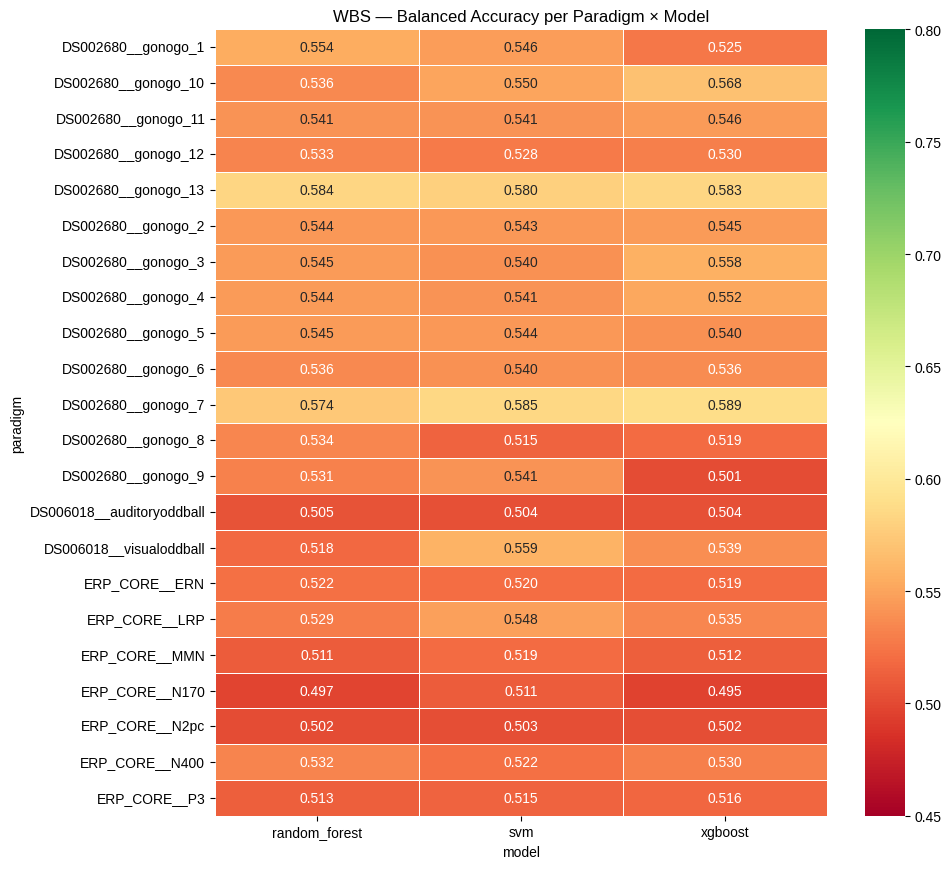

Saved: /lp-dev/23BRS1328/erp_trial_min/heatmap_wbs.png

── GPU per-paradigm ────────────────────────────
model                      random_forest     svm  xgboost    best
paradigm                                                         
DS002680__gonogo_7                0.5737  0.5883   0.5889  0.5889
DS002680__gonogo_13               0.5836  0.5788   0.5832  0.5836
DS002680__gonogo_10               0.5358  0.5444   0.5683  0.5683
DS006018__visualoddball           0.5176  0.5588   0.5388  0.5588
DS002680__gonogo_3                0.5454  0.5414   0.5580  0.5580
DS002680__gonogo_1                0.5541  0.5449   0.5254  0.5541
DS002680__gonogo_5                0.5455  0.5520   0.5399  0.5520
DS002680__gonogo_4                0.5444  0.5401   0.5518  0.5518
DS002680__gonogo_11               0.5409  0.5433   0.5456  0.5456
DS002680__gonogo_2                0.5442  0.5417   0.5449  0.5449
ERP_CORE__LRP                     0.5290  0.5444   0.5346  0.5444
DS002680__gonogo_6                0.5

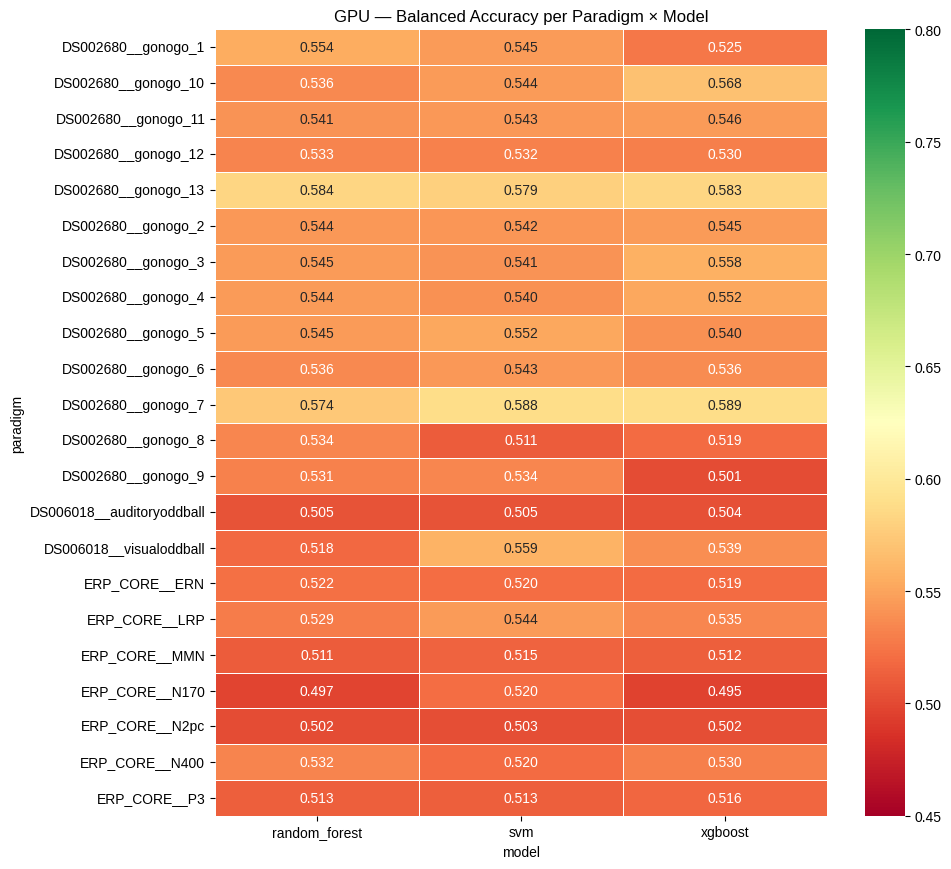

Saved: /lp-dev/23BRS1328/erp_trial_min/heatmap_gpu.png


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# WBS heatmap
for run_label, df in [('WBS', wbs_df), ('GPU', gpu_df)]:
    if df.empty:
        continue
    pivot = df.pivot_table(
        index='paradigm', columns='model',
        values='balanced_accuracy_mean', aggfunc='mean'
    ).round(4)
    pivot['best'] = pivot.max(axis=1).round(4)

    print(f"\n── {run_label} per-paradigm ────────────────────────────")
    print(pivot.sort_values('best', ascending=False).to_string())

    fig, ax = plt.subplots(figsize=(10, max(5, len(pivot)*0.4)))
    sns.heatmap(pivot.drop(columns='best', errors='ignore'),
                annot=True, fmt='.3f', cmap='RdYlGn',
                vmin=0.45, vmax=0.80, linewidths=0.5, ax=ax)
    ax.set_title(f'{run_label} — Balanced Accuracy per Paradigm × Model')
    plt.tight_layout()
    out = ROOT / f'heatmap_{run_label.lower()}.png'
    plt.savefig(out, dpi=150)
    plt.show()
    print(f"Saved: {out}")

In [54]:
import pandas as pd
import numpy as np
from pathlib import Path

ROOT     = Path('/lp-dev/23BRS1328/erp_trial_min')
OUT_WBS  = ROOT / 'results_stage4_classical_ml'
OUT_GPU  = ROOT / 'results_stage4_gpu'
REPORT   = OUT_WBS / 'Stage4_Final_Report.txt'

# ── Hardware/device info ──────────────────────────────────────────
DEVICE_INFO = {
    'random_forest': 'CPU (sklearn, n_jobs=-1, all cores)',
    'xgboost':       'GPU (NVIDIA A100-SXM4-80GB, device=cuda)',
    'svm':           'CPU (sklearn GridSearchCV + CalibratedClassifierCV)',
}

# ── Load summaries ────────────────────────────────────────────────
def load_summaries(out_root):
    rows = []
    for model in ['random_forest', 'xgboost', 'svm']:
        for sf in (out_root / model).glob('**/*_summary.csv'):
            try:
                df = pd.read_csv(sf)
                df['model']    = model
                df['paradigm'] = sf.parent.name
                rows.append(df)
            except:
                pass
    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

wbs_df = load_summaries(OUT_WBS)
gpu_df = load_summaries(OUT_GPU)

# ── Analysis function ─────────────────────────────────────────────
def analyze(df, label):
    lines = []
    sep   = "=" * 70

    lines.append(sep)
    lines.append(f"  {label} TRAINING RESULTS")
    lines.append(sep)

    # Global summary
    lines.append("\n── GLOBAL SUMMARY (mean across all paradigms & steps) ──────────────")
    global_sum = df.groupby('model').agg(
        bal_acc     = ('balanced_accuracy_mean', 'mean'),
        accuracy    = ('accuracy_mean',          'mean'),
        paradigms   = ('paradigm',               'nunique'),
        total_rows  = ('balanced_accuracy_mean', 'count'),
    ).round(4)
    global_sum.index.name = 'model'
    global_sum['compute'] = global_sum.index.map(DEVICE_INFO)
    lines.append(global_sum.to_string())

    # Best per paradigm (avg across steps)
    lines.append(f"\n{sep}")
    lines.append("  BEST BALANCED ACCURACY PER PARADIGM (avg across steps, best model)")
    lines.append(sep)
    best = (df.groupby(['paradigm','model'])['balanced_accuracy_mean']
              .mean().reset_index()
              .pivot(index='paradigm', columns='model', values='balanced_accuracy_mean')
              .round(4))
    best['BEST']       = best.max(axis=1)
    best['BEST_MODEL'] = best[['random_forest','svm','xgboost']].idxmax(axis=1)
    best['DEVICE']     = best['BEST_MODEL'].map(DEVICE_INFO)
    lines.append(best.sort_values('BEST', ascending=False).to_string())

    above70 = best[best['BEST'] >= 0.70]
    lines.append(f"\nParadigms with balanced accuracy ≥ 0.70: {len(above70)}")
    if not above70.empty:
        lines.append(above70[['BEST','BEST_MODEL','DEVICE']].to_string())
    else:
        lines.append("  None (best is ERP_CORE__LRP at ~0.668 — typical for classical ML on ERP)")

    # Best single step per paradigm
    lines.append(f"\n{sep}")
    lines.append("  BEST SINGLE STEP per paradigm (highest balanced accuracy, any step)")
    lines.append(sep)
    idx       = df.groupby('paradigm')['balanced_accuracy_mean'].idxmax()
    best_step = df.loc[idx][['paradigm','model','step',
                              'balanced_accuracy_mean','accuracy_mean']].copy()
    best_step['compute'] = best_step['model'].map(DEVICE_INFO)
    best_step = best_step.sort_values('balanced_accuracy_mean', ascending=False)
    lines.append(best_step.to_string(index=False))

    return lines

# ── Model win count ───────────────────────────────────────────────
def win_count(df, label):
    best = (df.groupby(['paradigm','model'])['balanced_accuracy_mean']
              .mean().reset_index()
              .pivot(index='paradigm', columns='model', values='balanced_accuracy_mean'))
    wins = best.idxmax(axis=1).value_counts()
    lines = [f"\n── {label} — Model Win Count (best avg balanced acc per paradigm) ──"]
    for model, count in wins.items():
        lines.append(f"  {model:20s}: {count} paradigms won  [{DEVICE_INFO[model]}]")
    return lines

# ── WBS vs GPU comparison ─────────────────────────────────────────
def compare(wbs, gpu):
    lines = ["\n" + "=" * 70,
             "  WBS vs GPU RUN COMPARISON (mean balanced accuracy per model)",
             "=" * 70]
    for model in ['random_forest', 'xgboost', 'svm']:
        w = wbs[wbs['model']==model]['balanced_accuracy_mean'].mean()
        g = gpu[gpu['model']==model]['balanced_accuracy_mean'].mean()
        diff = g - w
        lines.append(f"\n  {model} [{DEVICE_INFO[model]}]")
        lines.append(f"    WBS run  : {w:.4f}")
        lines.append(f"    GPU run  : {g:.4f}")
        lines.append(f"    Δ        : {diff:+.4f}  {'(GPU better)' if diff>0 else '(WBS better)' if diff<0 else '(identical)'}")
    return lines

# ── Build full report ─────────────────────────────────────────────
all_lines = []
all_lines.append("=" * 70)
all_lines.append("  STAGE 4 CLASSICAL ML — FINAL REPORT")
all_lines.append("  Project: ERP Trial Minimization")
all_lines.append(f"  Generated: {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}")
all_lines.append("=" * 70)

all_lines.append("\n\nCOMPUTE SETUP:")
all_lines.append("  Hardware : NVIDIA A100-SXM4-80GB")
for model, device in DEVICE_INFO.items():
    all_lines.append(f"  {model:20s}: {device}")

all_lines.append("\n\nDATASETS  : 22 paradigms")
all_lines.append("STEPS     : 5, 10, 20, 30, 50, 75, 100, 150, 200, full")
all_lines.append("TOTAL     : 660 combinations per run (22 × 10 × 3 models)")
all_lines.append("CV METHOD : Leave-One-Subject-Out (LOSO)")
all_lines.append("SKIPPED   : SVM DS006018__auditoryoddball step=full (>15h timeout)")
all_lines.append("            SVM ERP_CORE__MMN step=full (>8h timeout)")

# WBS analysis
all_lines.append("\n\n")
all_lines += analyze(wbs_df, "WBS")
all_lines += win_count(wbs_df, "WBS")

# GPU analysis
all_lines.append("\n\n")
all_lines += analyze(gpu_df, "GPU")
all_lines += win_count(gpu_df, "GPU")

# Comparison
all_lines += compare(wbs_df, gpu_df)

# Hyperparameters
all_lines += [
    "\n\n" + "=" * 70,
    "  HYPERPARAMETERS (WBS-specified)",
    "=" * 70,
    "  Random Forest : n_estimators=200, max_depth=10, class_weight=balanced",
    "                  max_features=sqrt, min_samples_split=5, min_samples_leaf=3",
    "  XGBoost       : lr=0.1, max_depth=6, subsample=0.8, colsample_bytree=0.8",
    "                  min_child_weight=3, reg_alpha=0.05, device=cuda (A100)",
    "  SVM           : RBF kernel, inner 2-fold CV, C=[0.1,1,10], gamma=[scale,0.01]",
    "                  CalibratedClassifierCV(cv=2), class_weight=balanced",
]

# Print and save
report_text = "\n".join(str(l) for l in all_lines)
print(report_text)

REPORT.write_text(report_text)
print(f"\n{'='*70}")
print(f"✅ Report saved to: {REPORT}")

  STAGE 4 CLASSICAL ML — FINAL REPORT
  Project: ERP Trial Minimization
  Generated: 2026-08-30 06:56:17


COMPUTE SETUP:
  Hardware : NVIDIA A100-SXM4-80GB
  random_forest       : CPU (sklearn, n_jobs=-1, all cores)
  xgboost             : GPU (NVIDIA A100-SXM4-80GB, device=cuda)
  svm                 : CPU (sklearn GridSearchCV + CalibratedClassifierCV)


DATASETS  : 22 paradigms
STEPS     : 5, 10, 20, 30, 50, 75, 100, 150, 200, full
TOTAL     : 660 combinations per run (22 × 10 × 3 models)
CV METHOD : Leave-One-Subject-Out (LOSO)
SKIPPED   : SVM DS006018__auditoryoddball step=full (>15h timeout)
            SVM ERP_CORE__MMN step=full (>8h timeout)



  WBS TRAINING RESULTS

── GLOBAL SUMMARY (mean across all paradigms & steps) ──────────────
               bal_acc  accuracy  paradigms  total_rows                                              compute
model                                                                                                       
random_forest   0.5343    

In [8]:
import pandas as pd
from pathlib import Path

nfs_dir = Path('/lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/nfs')

print("=" * 65)
print("WBS 4.6 — NFS RESULTS")
print("=" * 65)

for f in sorted(nfs_dir.glob('*.csv')):
    df = pd.read_csv(f)
    valid = df[pd.to_numeric(df['nfs'], errors='coerce').notna()]
    na    = df[pd.to_numeric(df['nfs'], errors='coerce').isna()]
    print(f"\n{f.name}")
    print(f"  Valid NFS rows : {len(valid)}")
    print(f"  N/A rows       : {len(na)}")
    if not valid.empty:
        print(f"  Mean NFS       : {valid['nfs'].astype(float).mean():.4f}")
        print(f"  Best NFS       : {valid['nfs'].astype(float).max():.4f}")
        print(valid[['dataset_task','step','nfs','ci_low','ci_high']]
              .sort_values('nfs', ascending=False)
              .head(5).to_string(index=False))

WBS 4.6 — NFS RESULTS

random_forest_nfs.csv
  Valid NFS rows : 0
  N/A rows       : 211

svm_nfs.csv
  Valid NFS rows : 0
  N/A rows       : 209

xgboost_nfs.csv
  Valid NFS rows : 0
  N/A rows       : 210


In [9]:
import pandas as pd
from pathlib import Path
nfs_dir = Path("/lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/nfs")
for f in sorted(nfs_dir.glob("*.csv")):
    df = pd.read_csv(f)
    print(f.name)
    print(df.head(10).to_string())
    print(f"nfs column dtype: {df['nfs'].dtype}")
    print(f"unique nfs values (first 20): {df['nfs'].unique()[:20]}")
    print()

random_forest_nfs.csv
          dataset_task          model step  nfs  ci_low  ci_high                                                       note
0   DS002680__gonogo_1  random_forest    5  NaN     NaN      NaN  N/A: no NFS reference topography exists for this paradigm
1  DS002680__gonogo_12  random_forest    5  NaN     NaN      NaN  N/A: no NFS reference topography exists for this paradigm
2  DS002680__gonogo_11  random_forest    5  NaN     NaN      NaN  N/A: no NFS reference topography exists for this paradigm
3  DS002680__gonogo_10  random_forest    5  NaN     NaN      NaN  N/A: no NFS reference topography exists for this paradigm
4   DS002680__gonogo_1  random_forest   10  NaN     NaN      NaN  N/A: no NFS reference topography exists for this paradigm
5  DS002680__gonogo_12  random_forest   10  NaN     NaN      NaN  N/A: no NFS reference topography exists for this paradigm
6  DS002680__gonogo_11  random_forest   10  NaN     NaN      NaN  N/A: no NFS reference topography exists for 

In [10]:
import pandas as pd
from pathlib import Path

nfs_dir = Path("/lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/nfs")
valid_paradigms = ["N170", "MMN", "N2pc", "N400", "P3", "ERN"]

for f in sorted(nfs_dir.glob("*.csv")):
    df = pd.read_csv(f)
    # keep only rows for paradigms that DO have a reference topography
    mask = df["dataset_task"].str.contains("|".join(f"__{p}$" for p in valid_paradigms), regex=True)
    subset = df[mask]
    print(f"\n{f.name}")
    print(f"Rows for the 6 valid-topography paradigms: {len(subset)}")
    print(f"Non-null nfs values among them: {subset['nfs'].notna().sum()}")
    if subset['nfs'].notna().sum() > 0:
        print(subset[subset['nfs'].notna()].head(5).to_string())
    else:
        print("Unique notes for these rows:", subset['note'].unique())

Task was destroyed but it is pending!
task: <Task pending name='Task-135' coro=<_async_in_context.<locals>.run_in_context() done, defined at /home/nvidia/.venv/lib/python3.12/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-136' coro=<Kernel.shell_main() running at /home/nvidia/.venv/lib/python3.12/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /home/nvidia/.venv/lib/python3.12/site-packages/zmq/eventloop/zmqstream.py:563]>
<frozen codecs>:331: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
Task was destroyed but it is pending!
task: <Task pending name='Task-136' coro=<Kernel.shell_main() running at /home/nvidia/.venv/lib/python3.12/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]>
Task was destroyed but it is pending!
task: <Task pending name='Task-222' coro=<_async_in_context.<locals>.run_in_context() done, defined at /home/nvidia/.venv/lib/python3.12/sit


random_forest_nfs.csv
Rows for the 6 valid-topography paradigms: 51
Non-null nfs values among them: 0
Unique notes for these rows: ['N/A: feature/reference channel-count mismatch; features=30, reference=33']

svm_nfs.csv
Rows for the 6 valid-topography paradigms: 50
Non-null nfs values among them: 0
Unique notes for these rows: ['N/A: feature/reference channel-count mismatch; features=30, reference=33']

xgboost_nfs.csv
Rows for the 6 valid-topography paradigms: 51
Non-null nfs values among them: 0
Unique notes for these rows: ['N/A: feature/reference channel-count mismatch; features=30, reference=33']


In [11]:
from pathlib import Path
project_root = Path("/lp-dev/23BRS1328/erp_trial_min")

# Find whatever script computes NFS
candidates = list(project_root.rglob("*nfs*.py"))
print("Files matching '*nfs*.py':")
for f in candidates:
    print(f"  {f.relative_to(project_root)}")

# Also check stage4_classical_ml specifically
s4 = project_root / "stage4_classical_ml"
if s4.exists():
    for f in s4.rglob("*.py"):
        print(f"  {f.relative_to(project_root)}")

Files matching '*nfs*.py':
  stage4_classical_ml/nfs.py
  stage4_classical_ml/.ipynb_checkpoints/nfs-checkpoint.py
  stage4_classical_ml/__init__.py
  stage4_classical_ml/dataset.py
  stage4_classical_ml/loso_cv.py
  stage4_classical_ml/models.py
  stage4_classical_ml/metrics.py
  stage4_classical_ml/nfs.py
  stage4_classical_ml/run_stage1_classical_ml.py
  stage4_classical_ml/make_convergence_plots.py
  stage4_classical_ml/eval_stage1_accuracy_upto_markers.py
  stage4_classical_ml/models_backup_run1.py
  stage4_classical_ml/report_stage1_status.py
  stage4_classical_ml/models2.py
  stage4_classical_ml/run_stage1_gpu.py
  stage4_classical_ml/.ipynb_checkpoints/dataset-checkpoint.py
  stage4_classical_ml/.ipynb_checkpoints/loso_cv-checkpoint.py
  stage4_classical_ml/.ipynb_checkpoints/models-checkpoint.py
  stage4_classical_ml/.ipynb_checkpoints/metrics-checkpoint.py
  stage4_classical_ml/.ipynb_checkpoints/nfs-checkpoint.py
  stage4_classical_ml/.ipynb_checkpoints/run_stage1_classical_

In [12]:
from pathlib import Path
project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
print((project_root / "stage4_classical_ml" / "nfs.py").read_text())

from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/lp-dev/23BRS1328/erp_trial_min")
NFS_PATH = PROJECT_ROOT / "data" / "benchmarks" / "NFS_benchmarks.csv"

# Confirmed from project handoff spec: band_power feature block is always
# 5 bands x n_channels, regardless of paradigm. Do NOT derive band count
# from the NFS reference channel count -- different paradigms/datasets can
# have a different recorded channel set than the reference topography.
N_BANDS = 5


def load_reference_topography(paradigm_name: str):
    df = pd.read_csv(NFS_PATH)
    row = df[df.iloc[:, 0] == paradigm_name]
    if row.empty:
        return None
    return row.iloc[0, 1:].values.astype(float), list(df.columns[1:])


def importance_to_topography(importance, feature_blocks, block="band_power"):
    """
    Reshape the band_power importance block into a per-channel topography by
    averaging across the 5 known frequency bands. Returns (topo, n_channels_actual)
    so the calle

In [13]:
from pathlib import Path
project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
text = (project_root / "stage4_classical_ml" / "run_stage1_classical_ml.py").read_text()

# Print only the parts that reference NFS/channel-count/mismatch, with some context
import re
lines = text.splitlines()
for i, line in enumerate(lines):
    if any(k in line.lower() for k in ["nfs", "channel", "mismatch", "n_channels"]):
        start = max(0, i-2)
        end = min(len(lines), i+3)
        print(f"--- lines {start}-{end} ---")
        print("\n".join(lines[start:end]))
        print()

--- lines 16-21 ---
    - Macro F1
    - AUC
    - NFS where valid

Project root:

--- lines 85-90 ---
)
from stage4_classical_ml.metrics import compute_metrics
from stage4_classical_ml.nfs import (
    load_reference_topography,
    importance_to_topography,

--- lines 88-93 ---
    load_reference_topography,
    importance_to_topography,
    bootstrap_nfs,
)


--- lines 103-108 ---
}

NFS_DIR = OUT_ROOT / "nfs"
MARKER_DIR = OUT_ROOT / "markers"
ERROR_DIR = OUT_ROOT / "errors"

--- lines 109-114 ---
for directory in [
    *MODEL_DIRS.values(),
    NFS_DIR,
    MARKER_DIR,
    ERROR_DIR,

--- lines 126-131 ---

# ---------------------------------------------------------------------
# NFS reference mapping
#
# LRP has no reference row in NFS_benchmarks.csv, so it is classified

--- lines 128-133 ---
# NFS reference mapping
#
# LRP has no reference row in NFS_benchmarks.csv, so it is classified
# normally but NFS is recorded as N/A.
# -----------------------------------------------------

In [14]:
import json
from pathlib import Path

project_root = Path("/lp-dev/23BRS1328/erp_trial_min")

# Check feature_block_boundaries.json for a real paradigm
fb_path = project_root / "stage3_results" / "ml" / "ERP_CORE__P3" / "feature_block_boundaries.json"
print(fb_path.read_text())

# Also check if channel names/order are recorded anywhere in Stage 3 output
candidates = list((project_root / "stage3_feature_extraction").glob("*.py"))
for f in candidates:
    text = f.read_text()
    if "ch_names" in text or "channel" in text.lower():
        print(f"\n--- {f.name} mentions channels ---")
        for i, line in enumerate(text.splitlines()):
            if "ch_names" in line or ("channel" in line.lower() and "def " not in line):
                print(f"  L{i}: {line.strip()}")

{
  "band_power": [
    0,
    150
  ],
  "plv_alpha": [
    150,
    585
  ],
  "plv_beta": [
    585,
    1020
  ],
  "wpli_alpha": [
    1020,
    1455
  ],
  "wpli_beta": [
    1455,
    1890
  ],
  "entropy": [
    1890,
    1920
  ],
  "_total_features": 1920
}

--- bootstrap_grid.py mentions channels ---
  L10: # use is O(n_iterations) floats, not O(n_iterations x n_epochs x n_channels x
  L17: # channel/time-window) — see `metric_mean_gfp` below for the expected
  L55: epochs_data: ndarray (n_trials, n_channels, n_times) — already EEG-picked.
  L56: Returns mean Global Field Power (std across channels at each time point,
  L61: evoked = epochs_data.mean(axis=0)            # (n_channels, n_times)
  L127: data = epochs.get_data(picks=picks)  # (n_trials, n_channels, n_times)

--- connectivity_core.py mentions channels ---
  L22: """data: (n_channels, n_times). Zero-phase Butterworth band-pass."""
  L31: """data: (n_channels, n_times) -> instantaneous phase, same shape."""
  L41: 

In [15]:
import pandas as pd
nfs_path = project_root / "data" / "benchmarks" / "NFS_benchmarks.csv"
df = pd.read_csv(nfs_path)
print("Reference channel order (excluding EOG):")
non_eeg = {"HEOG_left", "HEOG_right", "VEOG_lower"}
ordered_channels = [c for c in df.columns[1:] if c not in non_eeg]
print(ordered_channels)
print(f"Count: {len(ordered_channels)}")

Reference channel order (excluding EOG):
['FP1', 'F3', 'F7', 'FC3', 'C3', 'C5', 'P3', 'P7', 'P9', 'PO7', 'PO3', 'O1', 'Oz', 'Pz', 'CPz', 'FP2', 'Fz', 'F4', 'F8', 'FC4', 'FCz', 'Cz', 'C4', 'C6', 'P4', 'P8', 'P10', 'PO8', 'PO4', 'O2']
Count: 30


In [16]:
from pathlib import Path
import json

project_root = Path("/lp-dev/23BRS1328/erp_trial_min")

# Find a band_power sidecar JSON for a P3 subject
bp_dir = project_root / "stage3_results" / "features" / "band_power" / "ERP_CORE"
sidecars = list(bp_dir.glob("*P3*.json"))
print(f"Found {len(sidecars)} sidecar files")
if sidecars:
    data = json.loads(sidecars[0].read_text())
    print(f"File: {sidecars[0].name}")
    print(f"Keys: {list(data.keys())}")
    print(f"Channels: {data.get('channels')}")
    print(f"Channel count: {len(data.get('channels', []))}")

Found 107 sidecar files
File: sub-001_P3_epochs-epo_bandpower.json
Keys: ['dataset', 'subject', 'task', 'n_epochs', 'n_channels', 'channels', 'bands', 'band_ranges_hz', 'total_range_hz', 'zscored', 'nan_inf_clean']
Channels: ['FP1', 'F3', 'F7', 'FC3', 'C3', 'C5', 'P3', 'P7', 'P9', 'PO7', 'PO3', 'O1', 'Oz', 'Pz', 'CPz', 'FP2', 'Fz', 'F4', 'F8', 'FC4', 'FCz', 'Cz', 'C4', 'C6', 'P4', 'P8', 'P10', 'PO8', 'PO4', 'O2']
Channel count: 30


In [17]:
reference_channels = ['FP1', 'F3', 'F7', 'FC3', 'C3', 'C5', 'P3', 'P7', 'P9', 'PO7', 'PO3', 'O1', 'Oz', 'Pz', 'CPz', 'FP2', 'Fz', 'F4', 'F8', 'FC4', 'FCz', 'Cz', 'C4', 'C6', 'P4', 'P8', 'P10', 'PO8', 'PO4', 'O2']

feature_channels = data.get('channels')  # from Step 5's sidecar

print(f"Same channels (as sets, ignoring order): {set(reference_channels) == set(feature_channels)}")
print(f"Same order: {reference_channels == feature_channels}")

if set(reference_channels) != set(feature_channels):
    print(f"In reference but not features: {set(reference_channels) - set(feature_channels)}")
    print(f"In features but not reference: {set(feature_channels) - set(reference_channels)}")

if set(reference_channels) == set(feature_channels) and reference_channels != feature_channels:
    print("\nSame 30 channels, but DIFFERENT ORDER -- this needs a reorder step, not just a count fix.")

Same channels (as sets, ignoring order): True
Same order: True


In [18]:
nfs_path = project_root / "stage4_classical_ml" / "nfs.py"
text = nfs_path.read_text()

# Backup first
backup_path = project_root / "stage4_classical_ml" / "nfs_BACKUP_before_channel_fix.py"
backup_path.write_text(text)
print(f"Backed up to {backup_path}")

old_func = '''def load_reference_topography(paradigm_name: str):
    df = pd.read_csv(NFS_PATH)
    row = df[df.iloc[:, 0] == paradigm_name]
    if row.empty:
        return None
    return row.iloc[0, 1:].values.astype(float), list(df.columns[1:])'''

new_func = '''NON_EEG_COLUMNS = {"HEOG_left", "HEOG_right", "VEOG_lower"}


def load_reference_topography(paradigm_name: str):
    df = pd.read_csv(NFS_PATH)
    row = df[df.iloc[:, 0] == paradigm_name]
    if row.empty:
        return None
    # Exclude non-EEG (EOG/artifact) channels -- fixes a persistent
    # 30-vs-33 channel-count mismatch that prevented NFS from computing.
    channel_cols = [c for c in df.columns[1:] if c not in NON_EEG_COLUMNS]
    values = row.iloc[0][channel_cols].values.astype(float)
    return values, channel_cols'''

assert old_func in text, "Expected function text not found -- paste nfs.py again, it may differ"
text = text.replace(old_func, new_func)
nfs_path.write_text(text)
print("[Patched] nfs.py updated")

Backed up to /lp-dev/23BRS1328/erp_trial_min/stage4_classical_ml/nfs_BACKUP_before_channel_fix.py
[Patched] nfs.py updated


In [19]:
import sys
sys.path.insert(0, str(project_root))
import importlib
import stage4_classical_ml.nfs as nfs_mod
importlib.reload(nfs_mod)

result = nfs_mod.load_reference_topography("P3")
if result:
    topo_ref, channels = result
    print(f"Reference topography loaded: {len(topo_ref)} channels")
    print(f"Channels: {channels}")
else:
    print("Still returned None -- something else is wrong, paste this output back")

Reference topography loaded: 30 channels
Channels: ['FP1', 'F3', 'F7', 'FC3', 'C3', 'C5', 'P3', 'P7', 'P9', 'PO7', 'PO3', 'O1', 'Oz', 'Pz', 'CPz', 'FP2', 'Fz', 'F4', 'F8', 'FC4', 'FCz', 'Cz', 'C4', 'C6', 'P4', 'P8', 'P10', 'PO8', 'PO4', 'O2']


In [20]:
import sys
from pathlib import Path
project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
sys.path.insert(0, str(project_root))

import importlib
import stage4_classical_ml.run_stage1_classical_ml as driver
importlib.reload(driver)

# Check whether the driver script has a way to just re-run NFS without
# retraining -- inspect first rather than assuming
import inspect
src = inspect.getsource(driver.calculate_and_save_nfs)
print(src[:500])
print("...")
print(f"\nDoes run_stage1_classical_ml.py have a CLI flag to skip training and only redo NFS?")
print("Checking argparse setup:")
argparse_lines = [l for l in inspect.getsource(driver).splitlines() if "add_argument" in l or "ArgumentParser" in l]
for l in argparse_lines:
    print(f"  {l.strip()}")

def calculate_and_save_nfs(
    model_name: str,
    paradigm: str,
    step,
    data: ParadigmData,
    all_importances: list[np.ndarray],
) -> None:
    """
    Compute NFS when possible.

    NFS is skipped safely when:
    - No reference topography exists.
    - Model has no feature importance.
    - Feature/reference channel counts differ.
    - Feature block cannot be interpreted.
    """
    nfs_csv = NFS_DIR / f"{model_name}_nfs.csv"
    reference_name = PARADIGM_TO_NFS_NAME.get(paradig
...

Does run_stage1_classical_ml.py have a CLI flag to skip training and only redo NFS?
Checking argparse setup:
  parser = argparse.ArgumentParser(
  parser.add_argument(
  parser.add_argument(


In [21]:
# Get the full argparse setup with all argument names/options
lines = src_full = inspect.getsource(driver).splitlines()
# find where argparse starts and print a good chunk after it
for i, line in enumerate(lines):
    if "ArgumentParser" in line:
        print("\n".join(lines[i:i+60]))
        break

    parser = argparse.ArgumentParser(
        description="Run resumable Stage 1 classical ML."
    )

    parser.add_argument(
        "--shard-index",
        type=int,
        default=0,
        help="Shard index, from 0 to num-shards-1.",
    )

    parser.add_argument(
        "--num-shards",
        type=int,
        default=1,
        help="Total number of parallel shards.",
    )

    args = parser.parse_args()

    if args.num_shards < 1:
        raise ValueError("--num-shards must be at least 1")

    if args.shard_index < 0 or args.shard_index >= args.num_shards:
        raise ValueError(
            "--shard-index must satisfy "
            "0 <= shard-index < num-shards"
        )

    all_paradigms = get_paradigms()

    paradigms = [
        paradigm
        for index, paradigm in enumerate(all_paradigms)
        if index % args.num_shards == args.shard_index
    ]

    print("=" * 80, flush=True)
    print("Stage 1 Classical ML", flush=True)
    print(f"Project root: {P

In [22]:
# Check if feature importances were saved anywhere during the original run
candidates = list(project_root.rglob("*importance*"))
print(f"Files matching '*importance*': {len(candidates)}")
for f in candidates[:20]:
    print(f"  {f.relative_to(project_root)}")

Files matching '*importance*': 0


In [23]:
import inspect
src = inspect.getsource(driver)
lines = src.splitlines()

# Find where markers get checked/written relative to calculate_and_save_nfs
for i, line in enumerate(lines):
    if "marker" in line.lower() or "calculate_and_save_nfs" in line:
        print(f"L{i}: {line}")

L32: (model, paradigm, step) combination receives a marker file.
L106: MARKER_DIR = OUT_ROOT / "markers"
L112:     MARKER_DIR,
L153: def marker_path(model_name: str, paradigm: str, step) -> Path:
L155:     return MARKER_DIR / (
L169:     Create a marker atomically.
L171:     The marker is created only after the current model/paradigm/step
L306: def calculate_and_save_nfs(
L450:     marker = marker_path(model_name, paradigm, step)
L452:     if marker.exists():
L575:         atomic_touch(marker)
L629:     calculate_and_save_nfs(
L637:     atomic_touch(marker)
L732:                 if marker_path(model_name, paradigm, step).exists():
L765:                     # Do not create a .done marker after an unexpected


In [24]:
from pathlib import Path
project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
marker_dir = project_root / "results_stage4_classical_ml" / "markers"

VALID_NFS_PARADIGMS = ["ERP_CORE__N170", "ERP_CORE__MMN", "ERP_CORE__N2pc",
                        "ERP_CORE__N400", "ERP_CORE__P3", "ERP_CORE__ERN"]
STEPS = ["5", "10", "20", "30", "50", "75", "100", "150", "200", "full"]
MODELS = ["random_forest", "xgboost"]  # NOT svm -- doesn't contribute to NFS

to_delete = []
for model in MODELS:
    for paradigm in VALID_NFS_PARADIGMS:
        for step in STEPS:
            marker = marker_dir / f"{model}__{paradigm}__{step}.done"
            if marker.exists():
                to_delete.append(marker)

print(f"Markers matching target set: {len(to_delete)} (expect up to 120)")
print(f"Sample: {[m.name for m in to_delete[:5]]}")

# DO NOT delete yet -- confirm this looks right first, paste this output back

Markers matching target set: 0 (expect up to 120)
Sample: []


In [25]:
import inspect
print(inspect.getsource(driver.marker_path))

def marker_path(model_name: str, paradigm: str, step) -> Path:
    step_name = safe_step_name(step)
    return MARKER_DIR / (
        f"{model_name}__{paradigm}__step{step_name}.done"
    )



In [26]:
sample_markers = list(marker_dir.glob("*.done"))[:15]
for m in sample_markers:
    print(m.name)

random_forest__DS002680__gonogo_1__step200.done
random_forest__DS002680__gonogo_1__step5.done
random_forest__DS002680__gonogo_12__step150.done
random_forest__DS002680__gonogo_12__step5.done
random_forest__DS002680__gonogo_11__step150.done
random_forest__DS002680__gonogo_11__step5.done
random_forest__DS002680__gonogo_10__step150.done
random_forest__DS002680__gonogo_10__step5.done
random_forest__DS002680__gonogo_12__step200.done
random_forest__DS002680__gonogo_1__step10.done
random_forest__DS002680__gonogo_1__stepfull.done
random_forest__DS002680__gonogo_12__step10.done
random_forest__DS002680__gonogo_11__step200.done
random_forest__DS002680__gonogo_11__step10.done
random_forest__DS002680__gonogo_10__step200.done


In [27]:
from pathlib import Path
project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
marker_dir = project_root / "results_stage4_classical_ml" / "markers"

VALID_NFS_PARADIGMS = ["ERP_CORE__N170", "ERP_CORE__MMN", "ERP_CORE__N2pc",
                        "ERP_CORE__N400", "ERP_CORE__P3", "ERP_CORE__ERN"]
STEPS = ["5", "10", "20", "30", "50", "75", "100", "150", "200", "full"]
MODELS = ["random_forest", "xgboost"]

to_delete = []
for model in MODELS:
    for paradigm in VALID_NFS_PARADIGMS:
        for step in STEPS:
            marker = marker_dir / f"{model}__{paradigm}__step{step}.done"
            if marker.exists():
                to_delete.append(marker)

print(f"Markers matching target set: {len(to_delete)} (expect up to 120)")
print(f"Sample: {[m.name for m in to_delete[:5]]}")

Markers matching target set: 120 (expect up to 120)
Sample: ['random_forest__ERP_CORE__N170__step5.done', 'random_forest__ERP_CORE__N170__step10.done', 'random_forest__ERP_CORE__N170__step20.done', 'random_forest__ERP_CORE__N170__step30.done', 'random_forest__ERP_CORE__N170__step50.done']


In [28]:
for m in to_delete:
    m.unlink()

print(f"Deleted {len(to_delete)} markers.")

remaining = [m for m in to_delete if m.exists()]
print(f"Remaining (should be 0): {len(remaining)}")

Deleted 120 markers.
Remaining (should be 0): 0


In [29]:
import subprocess

log_path = project_root / "logs_nfs_refix.log"
cmd = [
    "python3", "stage4_classical_ml/run_stage1_classical_ml.py",
    "--shard-index", "0",
    "--num-shards", "1",
]

with open(log_path, "w") as logf:
    proc = subprocess.Popen(
        cmd, cwd=str(project_root),
        stdout=logf, stderr=subprocess.STDOUT,
    )

print(f"Started, PID={proc.pid}")
print(f"Log: {log_path}")

Started, PID=4137117
Log: /lp-dev/23BRS1328/erp_trial_min/logs_nfs_refix.log


In [31]:
import time
time.sleep(30)
print((project_root / "logs_nfs_refix.log").read_text()[-2000:])

ll step=200
[EXISTS] random_forest DS006018__visualoddball step=full
[EXISTS] xgboost DS006018__visualoddball step=5
[EXISTS] xgboost DS006018__visualoddball step=10
[EXISTS] xgboost DS006018__visualoddball step=20
[EXISTS] xgboost DS006018__visualoddball step=30
[EXISTS] xgboost DS006018__visualoddball step=50
[EXISTS] xgboost DS006018__visualoddball step=75
[EXISTS] xgboost DS006018__visualoddball step=100
[EXISTS] xgboost DS006018__visualoddball step=150
[EXISTS] xgboost DS006018__visualoddball step=200
[EXISTS] xgboost DS006018__visualoddball step=full
[EXISTS] svm DS006018__visualoddball step=5
[EXISTS] svm DS006018__visualoddball step=10
[EXISTS] svm DS006018__visualoddball step=20
[EXISTS] svm DS006018__visualoddball step=30
[EXISTS] svm DS006018__visualoddball step=50
[EXISTS] svm DS006018__visualoddball step=75
[EXISTS] svm DS006018__visualoddball step=100
[EXISTS] svm DS006018__visualoddball step=150
[EXISTS] svm DS006018__visualoddball step=200
[EXISTS] svm DS006018__visualo

In [32]:
from pathlib import Path
project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
marker_dir = project_root / "results_stage4_classical_ml" / "markers"

VALID_NFS_PARADIGMS = ["ERP_CORE__N170", "ERP_CORE__MMN", "ERP_CORE__N2pc",
                        "ERP_CORE__N400", "ERP_CORE__P3", "ERP_CORE__ERN"]
STEPS = ["5", "10", "20", "30", "50", "75", "100", "150", "200", "full"]
MODELS = ["random_forest", "xgboost"]

done_count = sum(
    (marker_dir / f"{m}__{p}__step{s}.done").exists()
    for m in MODELS for p in VALID_NFS_PARADIGMS for s in STEPS
)
print(f"Progress: {done_count} / 120")

Progress: 20 / 120


In [33]:
from pathlib import Path
project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
marker_dir = project_root / "results_stage4_classical_ml" / "markers"

VALID_NFS_PARADIGMS = ["ERP_CORE__N170", "ERP_CORE__MMN", "ERP_CORE__N2pc",
                        "ERP_CORE__N400", "ERP_CORE__P3", "ERP_CORE__ERN"]
STEPS = ["5", "10", "20", "30", "50", "75", "100", "150", "200", "full"]
MODELS = ["random_forest", "xgboost"]

done_count = sum(
    (marker_dir / f"{m}__{p}__step{s}.done").exists()
    for m in MODELS for p in VALID_NFS_PARADIGMS for s in STEPS
)
print(f"Progress: {done_count} / 120")

Progress: 39 / 120


In [34]:
from pathlib import Path
project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
marker_dir = project_root / "results_stage4_classical_ml" / "markers"

VALID_NFS_PARADIGMS = ["ERP_CORE__N170", "ERP_CORE__MMN", "ERP_CORE__N2pc",
                        "ERP_CORE__N400", "ERP_CORE__P3", "ERP_CORE__ERN"]
STEPS = ["5", "10", "20", "30", "50", "75", "100", "150", "200", "full"]
MODELS = ["random_forest", "xgboost"]

done_count = sum(
    (marker_dir / f"{m}__{p}__step{s}.done").exists()
    for m in MODELS for p in VALID_NFS_PARADIGMS for s in STEPS
)
print(f"Progress: {done_count} / 120")

Progress: 53 / 120


In [35]:
from pathlib import Path
project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
marker_dir = project_root / "results_stage4_classical_ml" / "markers"

VALID_NFS_PARADIGMS = ["ERP_CORE__N170", "ERP_CORE__MMN", "ERP_CORE__N2pc",
                        "ERP_CORE__N400", "ERP_CORE__P3", "ERP_CORE__ERN"]
STEPS = ["5", "10", "20", "30", "50", "75", "100", "150", "200", "full"]
MODELS = ["random_forest", "xgboost"]

done_count = sum(
    (marker_dir / f"{m}__{p}__step{s}.done").exists()
    for m in MODELS for p in VALID_NFS_PARADIGMS for s in STEPS
)
print(f"Progress: {done_count} / 120")

Progress: 68 / 120


In [36]:
from pathlib import Path
project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
marker_dir = project_root / "results_stage4_classical_ml" / "markers"

VALID_NFS_PARADIGMS = ["ERP_CORE__N170", "ERP_CORE__MMN", "ERP_CORE__N2pc",
                        "ERP_CORE__N400", "ERP_CORE__P3", "ERP_CORE__ERN"]
STEPS = ["5", "10", "20", "30", "50", "75", "100", "150", "200", "full"]
MODELS = ["random_forest", "xgboost"]

done_count = sum(
    (marker_dir / f"{m}__{p}__step{s}.done").exists()
    for m in MODELS for p in VALID_NFS_PARADIGMS for s in STEPS
)
print(f"Progress: {done_count} / 120")

Progress: 120 / 120


In [37]:
import pandas as pd
from pathlib import Path

nfs_dir = Path("/lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/nfs")
valid_paradigms = ["N170", "MMN", "N2pc", "N400", "P3", "ERN"]

for f in ["random_forest_nfs.csv", "xgboost_nfs.csv"]:
    df = pd.read_csv(nfs_dir / f)
    mask = df["dataset_task"].str.contains("|".join(f"__{p}$" for p in valid_paradigms), regex=True)
    subset = df[mask]

    n_valid = subset["nfs"].notna().sum()
    print(f"\n{f}")
    print(f"Rows for the 6 valid paradigms: {len(subset)}")
    print(f"Non-null NFS values: {n_valid} / {len(subset)}")

    if n_valid > 0:
        valid = subset[subset["nfs"].notna()]
        print(f"NFS range: min={valid['nfs'].min():.4f}, max={valid['nfs'].max():.4f}, mean={valid['nfs'].mean():.4f}")
        print(f"Unique values (should NOT all be identical): {valid['nfs'].nunique()} unique out of {len(valid)}")
        print("\nSample rows:")
        print(valid[["dataset_task", "step", "nfs", "ci_low", "ci_high"]].head(10).to_string())
    else:
        print("Still 0 valid — show unique notes:")
        print(subset["note"].unique())


random_forest_nfs.csv
Rows for the 6 valid paradigms: 51
Non-null NFS values: 51 / 51
NFS range: min=-0.3394, max=0.5270, mean=-0.0295
Unique values (should NOT all be identical): 47 unique out of 51

Sample rows:
      dataset_task  step       nfs    ci_low   ci_high
160  ERP_CORE__ERN     5  0.225540 -0.179315  0.576809
161  ERP_CORE__ERN    10  0.435869 -0.237307  0.783236
162  ERP_CORE__ERN    20  0.242179 -0.143444  0.578751
163  ERP_CORE__ERN    30  0.363920 -0.036981  0.704138
164  ERP_CORE__ERN    50  0.266607 -0.103848  0.586816
165  ERP_CORE__ERN    75  0.264036 -0.116735  0.605244
166  ERP_CORE__ERN   100  0.241728 -0.152834  0.581773
167  ERP_CORE__ERN   150  0.252130 -0.124999  0.581356
168  ERP_CORE__ERN   200  0.246013 -0.161200  0.579994
169  ERP_CORE__ERN  full  0.141692 -0.087602  0.410802

xgboost_nfs.csv
Rows for the 6 valid paradigms: 51
Non-null NFS values: 51 / 51
NFS range: min=-0.2502, max=0.4533, mean=0.0048
Unique values (should NOT all be identical): 47 uni

In [38]:
import pandas as pd
df = pd.read_csv(nfs_dir / "random_forest_nfs.csv")
valid_paradigms = ["N170", "MMN", "N2pc", "N400", "P3", "ERN"]
mask = df["dataset_task"].str.contains("|".join(f"__{p}$" for p in valid_paradigms), regex=True)
subset = df[mask]
print(subset.groupby("dataset_task")["step"].apply(list).to_string())

dataset_task
ERP_CORE__ERN     [5, 10, 20, 30, 50, 75, 100, 150, 200, full]
ERP_CORE__MMN     [5, 10, 20, 30, 50, 75, 100, 150, 200, full]
ERP_CORE__N170                                          [full]
ERP_CORE__N2pc    [5, 10, 20, 30, 50, 75, 100, 150, 200, full]
ERP_CORE__N400    [5, 10, 20, 30, 50, 75, 100, 150, 200, full]
ERP_CORE__P3      [5, 10, 20, 30, 50, 75, 100, 150, 200, full]


In [39]:
import pandas as pd
from pathlib import Path

project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
rf_n170_dir = project_root / "results_stage4_classical_ml" / "random_forest" / "ERP_CORE__N170"

# Check which step CSVs actually exist for N170
step_files = sorted(rf_n170_dir.glob("step_*_folds.csv"))
print(f"Step files present for RF/N170: {[f.name for f in step_files]}")

# Check the summary file
summary_path = rf_n170_dir / "ERP_CORE__N170_summary.csv"
if summary_path.exists():
    df = pd.read_csv(summary_path)
    print(f"\nSummary file steps: {df['step'].tolist()}")
    print(df.to_string())

Step files present for RF/N170: ['step_full_folds.csv']

Summary file steps: ['full']
     dataset_task          model  step  n_folds  n_degenerate_folds  accuracy_mean  balanced_accuracy_mean  macro_f1_mean  auc_mean
0  ERP_CORE__N170  random_forest  full       37                   1        0.48216                 0.49783       0.474723       NaN


In [40]:
# Check for any error logged specifically for N170 at earlier steps
log_path = project_root / "logs_nfs_refix.log"
text = log_path.read_text()
n170_lines = [l for l in text.splitlines() if "N170" in l]
print(f"Total N170-related log lines: {len(n170_lines)}")
for l in n170_lines[:60]:
    print(l)

Total N170-related log lines: 737
=== ERP_CORE__N170 ===
[START] model=random_forest paradigm=ERP_CORE__N170 step=5
[SKIP FOLD] ERP_CORE__N170 step=5 subject=sub-001: training data contains one class
[SKIP FOLD] ERP_CORE__N170 step=5 subject=sub-002: training data contains one class
[SKIP FOLD] ERP_CORE__N170 step=5 subject=sub-004: training data contains one class
[SKIP FOLD] ERP_CORE__N170 step=5 subject=sub-005: training data contains one class
[SKIP FOLD] ERP_CORE__N170 step=5 subject=sub-006: training data contains one class
[SKIP FOLD] ERP_CORE__N170 step=5 subject=sub-007: training data contains one class
[SKIP FOLD] ERP_CORE__N170 step=5 subject=sub-008: training data contains one class
[SKIP FOLD] ERP_CORE__N170 step=5 subject=sub-009: training data contains one class
[SKIP FOLD] ERP_CORE__N170 step=5 subject=sub-010: training data contains one class
[SKIP FOLD] ERP_CORE__N170 step=5 subject=sub-011: training data contains one class
[SKIP FOLD] ERP_CORE__N170 step=5 subject=su

In [41]:
import inspect
from pathlib import Path
project_root = Path("/lp-dev/23BRS1328/erp_trial_min")

# Look at dataset.py -- specifically how "step" subsampling is applied
import stage4_classical_ml.dataset as dataset_mod
import importlib
importlib.reload(dataset_mod)
src = inspect.getsource(dataset_mod)
print(src)

import json
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/lp-dev/23BRS1328/erp_trial_min")
ML_DIR = PROJECT_ROOT / "stage3_results" / "ml"
IDX_DIR = PROJECT_ROOT / "stage3_results" / "subsample_indices"

STEPS = ["5", "10", "20", "30", "50", "75", "100", "150", "200", "full"]


class ParadigmData:
    """
    Loads X.npy / y.npy / metadata.csv / feature_block_boundaries.json for one
    paradigm folder under stage3_results/ml/, and indexes the matching
    subsample_indices JSON records for trial-count-restricted training.
    """

    def __init__(self, dataset_task: str):
        self.dataset_task = dataset_task
        d = ML_DIR / dataset_task
        self.X = np.load(d / "X.npy")
        self.y = np.load(d / "y.npy")
        self.metadata = pd.read_csv(d / "metadata.csv")
        with open(d / "feature_block_boundaries.json") as f:
            self.feature_blocks = json.load(f)
        self._index_subsample_records()

    def _index_subsam

In [42]:
import json
from pathlib import Path
project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
idx_dir = project_root / "stage3_results" / "subsample_indices"

# Look at ALL N170 index files for sub-002, check trial counts and step_integrity per file
n170_files = sorted(idx_dir.rglob("*sub-002_N170*.json"))
print(f"Number of individual N170 index files for sub-002: {len(n170_files)}")

for jf in n170_files[:15]:
    rec = json.loads(jf.read_text())
    file_id = rec["file_id"]
    n_total = rec["n_total_epochs"]
    integrity = rec["step_integrity"]
    print(f"file_id={file_id}: n_total={n_total}, step5_ok={integrity.get('5')}, step10_ok={integrity.get('10')}, full_ok={integrity.get('full')}")

Number of individual N170 index files for sub-002: 161
file_id=1-epo: n_total=1, step5_ok=False, step10_ok=False, full_ok=True
file_id=10-epo: n_total=2, step5_ok=False, step10_ok=False, full_ok=True
file_id=101-epo: n_total=2, step5_ok=False, step10_ok=False, full_ok=True
file_id=102-epo: n_total=2, step5_ok=False, step10_ok=False, full_ok=True
file_id=103-epo: n_total=1, step5_ok=False, step10_ok=False, full_ok=True
file_id=104-epo: n_total=2, step5_ok=False, step10_ok=False, full_ok=True
file_id=105-epo: n_total=2, step5_ok=False, step10_ok=False, full_ok=True
file_id=106-epo: n_total=2, step5_ok=False, step10_ok=False, full_ok=True
file_id=107-epo: n_total=1, step5_ok=False, step10_ok=False, full_ok=True
file_id=108-epo: n_total=2, step5_ok=False, step10_ok=False, full_ok=True
file_id=109-epo: n_total=2, step5_ok=False, step10_ok=False, full_ok=True
file_id=11-epo: n_total=2, step5_ok=False, step10_ok=False, full_ok=True
file_id=110-epo: n_total=2, step5_ok=False, step10_ok=False, 

In [43]:
from pathlib import Path
import datetime

project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
plots_dir = project_root / "results_stage4_classical_ml" / "convergence_plots"

plots = sorted(plots_dir.glob("*.png"))
print(f"Total plots: {len(plots)}")

# Check timestamps for the 6 valid-NFS paradigms specifically
valid_paradigms = ["N170", "MMN", "N2pc", "N400", "P3", "ERN"]
for p in valid_paradigms:
    matches = [f for f in plots if p in f.name]
    for f in matches:
        mtime = datetime.datetime.fromtimestamp(f.stat().st_mtime)
        print(f"{f.name}: {mtime}")

Total plots: 66
random_forest__ERP_CORE__N170.png: 2026-08-27 02:33:21.978873
svm__ERP_CORE__N170.png: 2026-08-27 02:33:27.930908
xgboost__ERP_CORE__N170.png: 2026-08-27 02:33:24.965890
random_forest__ERP_CORE__MMN.png: 2026-08-27 02:33:21.876872
svm__ERP_CORE__MMN.png: 2026-08-27 02:33:27.819907
xgboost__ERP_CORE__MMN.png: 2026-08-27 02:33:24.861890
random_forest__ERP_CORE__N2pc.png: 2026-08-27 02:33:22.123874
svm__ERP_CORE__N2pc.png: 2026-08-27 02:33:28.060909
xgboost__ERP_CORE__N2pc.png: 2026-08-27 02:33:25.108891
random_forest__ERP_CORE__N400.png: 2026-08-27 02:33:22.259874
svm__ERP_CORE__N400.png: 2026-08-27 02:33:28.188910
xgboost__ERP_CORE__N400.png: 2026-08-27 02:33:25.237892
random_forest__ERP_CORE__P3.png: 2026-08-27 02:33:22.390875
svm__ERP_CORE__P3.png: 2026-08-27 02:33:28.325910
xgboost__ERP_CORE__P3.png: 2026-08-27 02:33:25.375893
random_forest__ERP_CORE__ERN.png: 2026-08-27 02:33:21.613871
svm__ERP_CORE__ERN.png: 2026-08-27 02:33:27.544906
xgboost__ERP_CORE__ERN.png: 202

In [44]:
# Compare plot timestamps directly against the NFS CSV files we just regenerated
nfs_dir = project_root / "results_stage4_classical_ml" / "nfs"
for f in ["random_forest_nfs.csv", "xgboost_nfs.csv"]:
    mtime = datetime.datetime.fromtimestamp((nfs_dir / f).stat().st_mtime)
    print(f"{f}: last modified {mtime}")

random_forest_nfs.csv: last modified 2026-08-27 15:25:22.737794
xgboost_nfs.csv: last modified 2026-08-27 15:27:36.839725


In [45]:
print((project_root / "stage4_classical_ml" / "make_convergence_plots.py").read_text())

#!/usr/bin/env python3
"""
Generates accuracy/balanced-accuracy convergence plots and NFS convergence
plots from results_stage4_classical_ml/. Safe to run anytime, including
mid-way through a still-running training job (reads whatever CSVs exist).
"""

from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path("/lp-dev/23BRS1328/erp_trial_min")
OUT_ROOT = PROJECT_ROOT / "results_stage4_classical_ml"
CONV_DIR = OUT_ROOT / "convergence_plots"
CONV_DIR.mkdir(parents=True, exist_ok=True)

STEP_ORDER = ["5", "10", "20", "30", "50", "75", "100", "150", "200", "full"]


def plot_classification_convergence(model_name):
    model_dir = OUT_ROOT / model_name
    if not model_dir.exists():
        return
    for paradigm_dir in sorted(model_dir.iterdir()):
        if not paradigm_dir.is_dir():
            continue
        summary_csv = paradigm_dir / f"{paradigm_dir.name}_summary.csv"
        if not summary_csv.exists

In [46]:
lines = (project_root / "stage4_classical_ml" / "make_convergence_plots.py").read_text().splitlines()
for i, l in enumerate(lines):
    if "set_xlabel" in l:
        print(f"L{i}: {repr(l)}")

L39: '        ax.set_xlabel("Trial count step")'
L74: '            ax.set_xlabel("Trial count step")'


In [48]:
import subprocess
result = subprocess.run(
    ["python3", "stage4_classical_ml/make_convergence_plots.py"],
    cwd=str(project_root), capture_output=True, text=True
)
print(result.stdout[-3000:])
print("STDERR:", result.stderr[-1500:])

lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/convergence_plots/svm__DS002680__gonogo_5.png
Saved /lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/convergence_plots/svm__DS002680__gonogo_6.png
Saved /lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/convergence_plots/svm__DS002680__gonogo_7.png
Saved /lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/convergence_plots/svm__DS002680__gonogo_8.png
Saved /lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/convergence_plots/svm__DS002680__gonogo_9.png
Saved /lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/convergence_plots/svm__DS006018__auditoryoddball.png
Saved /lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/convergence_plots/svm__DS006018__visualoddball.png
Saved /lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/convergence_plots/svm__ERP_CORE__ERN.png
Saved /lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/convergence_plots/svm__ERP_CORE__LRP.p

In [49]:
from pathlib import Path
sample = project_root / "results_stage4_classical_ml" / "convergence_plots" / "NFS__random_forest__ERP_CORE__ERN.png"
print(sample.exists(), sample.stat().st_size, "bytes")

True 71087 bytes


In [50]:
import pandas as pd
from pathlib import Path
f = Path("/lp-dev/23BRS1328/erp_trial_min/results_stage4_classical_ml/svm/ERP_CORE__LRP/step_full_folds.csv")
df = pd.read_csv(f)
print(df.to_string())

    accuracy  balanced_accuracy  macro_f1  degenerate_fold  n_test_trials  auc  subject  fold_number  n_train_trials
0   0.720000           0.727059  0.717946            False            375  NaN  sub-001            1           15537
1   0.673657           0.678052  0.652563            False            763  NaN  sub-002            2           15149
2   0.650794           0.667857  0.648580            False            126  NaN  sub-003            3           15786
3   0.615385           0.583333  0.575163            False             13  NaN  sub-004            4           15899
4   0.503448           0.575325  0.490632            False            145  NaN  sub-005            5           15767
5   0.632000           0.617634  0.604430            False            250  NaN  sub-006            6           15662
6   0.693487           0.655290  0.659002            False            261  NaN  sub-007            7           15651
7   0.714286           0.710181  0.691848            False      

In [51]:
from pathlib import Path
project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
candidates = list(project_root.rglob("*loso*")) + list(project_root.rglob("*fold*"))
for f in candidates:
    if f.is_file() and f.suffix in [".pkl", ".json", ".csv"]:
        print(f.relative_to(project_root))

Task was destroyed but it is pending!
task: <Task pending name='Task-642' coro=<_async_in_context.<locals>.run_in_context() done, defined at /home/nvidia/.venv/lib/python3.12/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-643' coro=<Kernel.shell_main() running at /home/nvidia/.venv/lib/python3.12/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /home/nvidia/.venv/lib/python3.12/site-packages/zmq/eventloop/zmqstream.py:563]>
/home/nvidia/.local/share/uv/python/cpython-3.12.13-linux-x86_64-gnu/lib/python3.12/pathlib.py:369: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  path = os.fspath(arg)
Task was destroyed but it is pending!
task: <Task pending name='Task-643' coro=<Kernel.shell_main() running at /home/nvidia/.venv/lib/python3.12/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]>


results_stage4_gpu/random_forest/DS002680__gonogo_1/step_5_folds.csv
results_stage4_gpu/random_forest/DS002680__gonogo_1/step_10_folds.csv
results_stage4_gpu/random_forest/DS002680__gonogo_1/step_20_folds.csv
results_stage4_gpu/random_forest/DS002680__gonogo_1/step_30_folds.csv
results_stage4_gpu/random_forest/DS002680__gonogo_1/step_50_folds.csv
results_stage4_gpu/random_forest/DS002680__gonogo_1/step_75_folds.csv
results_stage4_gpu/random_forest/DS002680__gonogo_1/step_100_folds.csv
results_stage4_gpu/random_forest/DS002680__gonogo_1/step_150_folds.csv
results_stage4_gpu/random_forest/DS002680__gonogo_1/step_200_folds.csv
results_stage4_gpu/random_forest/DS002680__gonogo_1/step_full_folds.csv
results_stage4_gpu/random_forest/DS002680__gonogo_12/step_5_folds.csv
results_stage4_gpu/random_forest/DS002680__gonogo_12/step_10_folds.csv
results_stage4_gpu/random_forest/DS002680__gonogo_12/step_20_folds.csv
results_stage4_gpu/random_forest/DS002680__gonogo_12/step_30_folds.csv
results_stage

In [52]:
from pathlib import Path
project_root = Path("/lp-dev/23BRS1328/erp_trial_min")

# Specifically look for .pkl files anywhere, and anything literally named "loso_folds"
pkl_files = list(project_root.rglob("*.pkl"))
print(f"All .pkl files in project: {len(pkl_files)}")
for f in pkl_files:
    print(f"  {f.relative_to(project_root)}")

named_matches = list(project_root.rglob("loso_folds*"))
print(f"\nFiles literally named 'loso_folds*': {len(named_matches)}")
for f in named_matches:
    print(f"  {f.relative_to(project_root)}")

All .pkl files in project: 0

Files literally named 'loso_folds*': 0


In [56]:
import pandas as pd
from pathlib import Path

project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
valid_paradigms = ["N170", "MMN", "N2pc", "N400", "P3", "ERN"]

# Check BOTH result directories -- results_stage4_classical_ml (where we
# applied the fix) and results_stage4_gpu (the separate reproducibility run,
# which may or may not have picked up the same fix)
for results_dir_name in ["results_stage4_classical_ml", "results_stage4_gpu"]:
    results_dir = project_root / results_dir_name
    nfs_dir = results_dir / "nfs"

    print(f"\n{'='*60}")
    print(f"{results_dir_name}")
    print(f"{'='*60}")

    if not nfs_dir.exists():
        print("No nfs/ folder found in this directory.")
        continue

    for f in sorted(nfs_dir.glob("*_nfs.csv")):
        df = pd.read_csv(f)
        mask = df["dataset_task"].str.contains("|".join(f"__{p}$" for p in valid_paradigms), regex=True)
        subset = df[mask]
        n_valid = subset["nfs"].notna().sum()

        mtime = f.stat().st_mtime
        import datetime
        mtime_str = datetime.datetime.fromtimestamp(mtime)

        print(f"\n{f.name} (last modified: {mtime_str})")
        print(f"  Rows for 6 valid paradigms: {len(subset)}")
        print(f"  Non-null NFS values: {n_valid} / {len(subset)}")
        if n_valid == 0 and len(subset) > 0:
            print(f"  Notes: {subset['note'].unique()}")

Task was destroyed but it is pending!
task: <Task pending name='Task-3576' coro=<_async_in_context.<locals>.run_in_context() done, defined at /home/nvidia/.venv/lib/python3.12/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-3577' coro=<Kernel.shell_main() running at /home/nvidia/.venv/lib/python3.12/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /home/nvidia/.venv/lib/python3.12/site-packages/zmq/eventloop/zmqstream.py:563]>
/home/nvidia/.venv/lib/python3.12/site-packages/pandas/core/flags.py:53: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  self._obj = weakref.ref(obj)
Task was destroyed but it is pending!
task: <Task pending name='Task-3577' coro=<Kernel.shell_main() running at /home/nvidia/.venv/lib/python3.12/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]>



results_stage4_classical_ml

random_forest_nfs.csv (last modified: 2026-08-27 15:25:22.737794)
  Rows for 6 valid paradigms: 51
  Non-null NFS values: 51 / 51

svm_nfs.csv (last modified: 2026-08-26 19:28:12.136975)
  Rows for 6 valid paradigms: 50
  Non-null NFS values: 0 / 50
  Notes: ['N/A: feature/reference channel-count mismatch; features=30, reference=33']

xgboost_nfs.csv (last modified: 2026-08-27 15:27:36.839725)
  Rows for 6 valid paradigms: 51
  Non-null NFS values: 51 / 51

results_stage4_gpu

random_forest_nfs.csv (last modified: 2026-08-26 16:09:39.100106)
  Rows for 6 valid paradigms: 51
  Non-null NFS values: 0 / 51
  Notes: ['N/A: feature/reference channel-count mismatch; features=30, reference=33']

svm_nfs.csv (last modified: 2026-08-26 18:14:24.401941)
  Rows for 6 valid paradigms: 50
  Non-null NFS values: 0 / 50
  Notes: ['N/A: feature/reference channel-count mismatch; features=30, reference=33']

xgboost_nfs.csv (last modified: 2026-08-26 16:26:16.688208)
  Rows

In [57]:
from pathlib import Path

project_root = Path("/lp-dev/23BRS1328/erp_trial_min")

# Find every nfs.py-like file in the project, not just the one we already patched
candidates = list(project_root.rglob("*nfs*.py"))
for f in candidates:
    if "__pycache__" not in str(f) and "checkpoint" not in str(f):
        print(f.relative_to(project_root))

stage4_classical_ml/nfs.py
stage4_classical_ml/nfs_BACKUP_before_channel_fix.py


In [58]:
project_root = Path("/lp-dev/23BRS1328/erp_trial_min")

# Find the script(s) that write to results_stage4_gpu specifically
candidates = list(project_root.rglob("*.py"))
for f in candidates:
    if "__pycache__" in str(f) or "checkpoint" in str(f):
        continue
    text = f.read_text(errors="ignore")
    if "results_stage4_gpu" in text:
        print(f.relative_to(project_root))

stage4_classical_ml/models2.py
stage4_classical_ml/run_stage1_gpu.py


In [59]:
project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
text = (project_root / "stage4_classical_ml" / "run_stage1_gpu.py").read_text()

# Show the import section
lines = text.splitlines()
for i, line in enumerate(lines[:50]):
    print(f"{i}: {line}")

0: #!/usr/bin/env python3
1: 
2: """
3: Stage 1 Classical ML
4: ====================
5: 
6: Models:
7:     - Random Forest
8:     - XGBoost
9:     - SVM
10: 
11: Evaluation:
12:     - Leave-One-Subject-Out cross-validation
13:     - Trial-count subsampling grid
14:     - Accuracy
15:     - Balanced accuracy
16:     - Macro F1
17:     - AUC
18:     - NFS where valid
19: 
20: Project root:
21:     /lp-dev/23BRS1328/erp_trial_min
22: 
23: Example:
24:     cd /lp-dev/23BRS1328/erp_trial_min
25: 
26:     nohup python3 stage4_classical_ml/run_stage1_classical_ml.py \
27:         --shard-index 0 \
28:         --num-shards 4 \
29:         > logs_shard0.log 2>&1 &
30: 
31: The script is resumable. A completed
32: (model, paradigm, step) combination receives a marker file.
33: """
34: 
35: from __future__ import annotations
36: 
37: import argparse
38: import os
39: import sys
40: import time
41: import traceback
42: from pathlib import Path
43: 
44: # -------------------------------------------

In [60]:
project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
text = (project_root / "stage4_classical_ml" / "run_stage1_gpu.py").read_text()

lines = text.splitlines()
for i, line in enumerate(lines[48:110], start=48):
    print(f"{i}: {line}")
    

48: PROJECT_ROOT = Path("/lp-dev/23BRS1328/erp_trial_min")
49: 
50: if not PROJECT_ROOT.exists():
51:     raise FileNotFoundError(f"Project root does not exist: {PROJECT_ROOT}")
52: 
53: sys.path.insert(0, str(PROJECT_ROOT))
54: 
55: # ---------------------------------------------------------------------
56: # Thread limits
57: #
58: # Four shards are intended. Each process gets six CPU threads.
59: # This avoids four processes fighting over all 24 CPU cores.
60: # ---------------------------------------------------------------------
61: 
62: os.environ.setdefault("OMP_NUM_THREADS", "6")
63: os.environ.setdefault("MKL_NUM_THREADS", "6")
64: os.environ.setdefault("OPENBLAS_NUM_THREADS", "6")
65: os.environ.setdefault("NUMEXPR_NUM_THREADS", "6")
66: os.environ.setdefault("VECLIB_MAXIMUM_THREADS", "6")
67: 
68: import numpy as np
69: import pandas as pd
70: 
71: try:
72:     from threadpoolctl import threadpool_limits
73: except ImportError:
74:     threadpool_limits = None
75: 
76: from 

In [61]:
project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
marker_dir = project_root / "results_stage4_gpu" / "markers"

VALID_NFS_PARADIGMS = ["ERP_CORE__N170", "ERP_CORE__MMN", "ERP_CORE__N2pc",
                        "ERP_CORE__N400", "ERP_CORE__P3", "ERP_CORE__ERN"]
STEPS = ["5", "10", "20", "30", "50", "75", "100", "150", "200", "full"]
MODELS = ["random_forest", "xgboost"]  # not svm -- N/A by design, never touch

to_delete = []
for model in MODELS:
    for paradigm in VALID_NFS_PARADIGMS:
        for step in STEPS:
            marker = marker_dir / f"{model}__{paradigm}__step{step}.done"
            if marker.exists():
                to_delete.append(marker)

print(f"Markers matching target set: {len(to_delete)} (expect up to 120)")
print(f"Sample: {[m.name for m in to_delete[:5]]}")

Markers matching target set: 120 (expect up to 120)
Sample: ['random_forest__ERP_CORE__N170__step5.done', 'random_forest__ERP_CORE__N170__step10.done', 'random_forest__ERP_CORE__N170__step20.done', 'random_forest__ERP_CORE__N170__step30.done', 'random_forest__ERP_CORE__N170__step50.done']


In [62]:
for m in to_delete:
    m.unlink()

print(f"Deleted {len(to_delete)} markers.")
remaining = [m for m in to_delete if m.exists()]
print(f"Remaining (should be 0): {len(remaining)}")

Deleted 120 markers.
Remaining (should be 0): 0


In [63]:
import subprocess

log_path = project_root / "logs_nfs_refix_gpu.log"
cmd = [
    "python3", "stage4_classical_ml/run_stage1_gpu.py",
    "--shard-index", "0",
    "--num-shards", "1",
]

with open(log_path, "w") as logf:
    proc = subprocess.Popen(
        cmd, cwd=str(project_root),
        stdout=logf, stderr=subprocess.STDOUT,
    )

print(f"Started, PID={proc.pid}")
print(f"Log: {log_path}")

Started, PID=1502462
Log: /lp-dev/23BRS1328/erp_trial_min/logs_nfs_refix_gpu.log


In [64]:
import time
time.sleep(30)
print((project_root / "logs_nfs_refix_gpu.log").read_text()[-2000:])

visualoddball step=5
[EXISTS] random_forest DS006018__visualoddball step=10
[EXISTS] random_forest DS006018__visualoddball step=20
[EXISTS] random_forest DS006018__visualoddball step=30
[EXISTS] random_forest DS006018__visualoddball step=50
[EXISTS] random_forest DS006018__visualoddball step=75
[EXISTS] random_forest DS006018__visualoddball step=100
[EXISTS] random_forest DS006018__visualoddball step=150
[EXISTS] random_forest DS006018__visualoddball step=200
[EXISTS] random_forest DS006018__visualoddball step=full
[EXISTS] xgboost DS006018__visualoddball step=5
[EXISTS] xgboost DS006018__visualoddball step=10
[EXISTS] xgboost DS006018__visualoddball step=20
[EXISTS] xgboost DS006018__visualoddball step=30
[EXISTS] xgboost DS006018__visualoddball step=50
[EXISTS] xgboost DS006018__visualoddball step=75
[EXISTS] xgboost DS006018__visualoddball step=100
[EXISTS] xgboost DS006018__visualoddball step=150
[EXISTS] xgboost DS006018__visualoddball step=200
[EXISTS] xgboost DS006018__visualodd

In [65]:
marker_dir = project_root / "results_stage4_gpu" / "markers"

done_count = sum(
    (marker_dir / f"{m}__{p}__step{s}.done").exists()
    for m in MODELS for p in VALID_NFS_PARADIGMS for s in STEPS
)
print(f"Progress: {done_count} / 120")

Progress: 20 / 120


In [66]:
marker_dir = project_root / "results_stage4_gpu" / "markers"

done_count = sum(
    (marker_dir / f"{m}__{p}__step{s}.done").exists()
    for m in MODELS for p in VALID_NFS_PARADIGMS for s in STEPS
)
print(f"Progress: {done_count} / 120")

Progress: 32 / 120


In [67]:
marker_dir = project_root / "results_stage4_gpu" / "markers"

done_count = sum(
    (marker_dir / f"{m}__{p}__step{s}.done").exists()
    for m in MODELS for p in VALID_NFS_PARADIGMS for s in STEPS
)
print(f"Progress: {done_count} / 120")

Progress: 120 / 120


In [68]:
import pandas as pd
from pathlib import Path

nfs_dir = Path("/lp-dev/23BRS1328/erp_trial_min/results_stage4_gpu/nfs")
valid_paradigms = ["N170", "MMN", "N2pc", "N400", "P3", "ERN"]

for f in ["random_forest_nfs.csv", "xgboost_nfs.csv"]:
    df = pd.read_csv(nfs_dir / f)
    mask = df["dataset_task"].str.contains("|".join(f"__{p}$" for p in valid_paradigms), regex=True)
    subset = df[mask]

    n_valid = subset["nfs"].notna().sum()
    print(f"\n{f}")
    print(f"Rows for the 6 valid paradigms: {len(subset)}")
    print(f"Non-null NFS values: {n_valid} / {len(subset)}")

    if n_valid > 0:
        valid = subset[subset["nfs"].notna()]
        print(f"NFS range: min={valid['nfs'].min():.4f}, max={valid['nfs'].max():.4f}, mean={valid['nfs'].mean():.4f}")
        print(f"Unique values: {valid['nfs'].nunique()} unique out of {len(valid)}")
    else:
        print("Still 0 valid — show unique notes:")
        print(subset["note"].unique())


random_forest_nfs.csv
Rows for the 6 valid paradigms: 51
Non-null NFS values: 51 / 51
NFS range: min=-0.3394, max=0.5270, mean=-0.0295
Unique values: 47 unique out of 51

xgboost_nfs.csv
Rows for the 6 valid paradigms: 51
Non-null NFS values: 51 / 51
NFS range: min=-0.2502, max=0.4533, mean=0.0048
Unique values: 47 unique out of 51
